# مرحله 04B پروژه FORCE
## Class-Pair Support and Quantile-Transport Registry

هدف این نوت‌بوک این است که قبل از ساخت مداخلات کلاس‌به‌کلاس مشخص کند برای هر:

```text
Outer Fold × Well Log × Source Lithology × Target Lithology
```

آیا Support کافی برای ساخت یک **Class-conditional quantile transport** معتبر وجود دارد یا نه.

مثلا برای:

```text
GR: Shale → Limestone-like
```

باید بدانیم:

- Shale و Limestone در Outer Training چند ردیف معتبر GR دارند؛
- هرکدام در چند چاه دیده شده‌اند؛
- در Outer Validation چند Sample معتبر Shale برای ارزیابی وجود دارد؛
- توزیع‌های GR هر دو کلاس IQR و تنوع کافی دارند؛
- Pair در چند Fold پایدار و قابل‌برآورد است.

این نوت‌بوک هنوز هیچ مدل یا Interventionی را اجرا نمی‌کند. فقط **Support registry، Quantile registry و Diagnostic plots** را می‌سازد.

## جهت‌دار بودن Pairها

`Shale → Limestone` و `Limestone → Shale` دو Pair جدا هستند. با ۱۲ کلاس، برای هر Feature تعداد ۱۳۲ Pair جهت‌دار داریم.

## جلوگیری از Leakage

Quantileهای هر Outer Fold فقط از چاه‌های Outer Training ساخته می‌شوند. Outer Validation فقط برای سنجش Support کلاس مبدأ استفاده می‌شود. Official Test در این مرحله استفاده نمی‌شود.

## Plotهای این نوت‌بوک

برای بررسی بصری، Plotهای زیر ساخته و ذخیره می‌شوند:

- تعداد ردیف و تعداد چاه هر Lithology؛
- Support کلاس‌ها در Foldهای مختلف؛
- Missingness هر Log در هر کلاس؛
- تعداد Pairهای Confirmatory، Descriptive و Not-estimable؛
- ماتریس جهت‌دار Support برای تک‌تک Logها؛
- نمودار فاصله توزیعی و Overlap Pairها؛
- Quantile curve و Quantile mapping برای Pairهای پیشنهادی Pilot.

تمام تصاویر در پوشه `plots` ذخیره می‌شوند.

In [1]:
import sys
import subprocess
import importlib.util

required = {
    "pandas": "pandas",
    "numpy": "numpy",
    "matplotlib": "matplotlib",
    "pyarrow": "pyarrow",
}

for module_name, package_name in required.items():
    if importlib.util.find_spec(module_name) is None:
        subprocess.check_call(
            [sys.executable, "-m", "pip", "install", "-q", package_name]
        )

print("Required packages are available.")

Required packages are available.


In [2]:
from pathlib import Path
from itertools import permutations
import gc
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 250)
pd.set_option("display.max_rows", 300)
pd.set_option("display.max_colwidth", 200)

EPSILON = 1e-12
np.random.seed(42)

# 1. تنظیمات و Thresholdهای ازپیش‌قفل‌شده

In [3]:
RUN_MODE = "full"  # "pilot" or "full"

ACTIVE_OUTER_FOLDS = [1] if RUN_MODE == "pilot" else [1, 2, 3, 4, 5]
ACTIVE_FEATURES = (
    ["GR", "RHOB"]
    if RUN_MODE == "pilot"
    else ["GR", "NPHI", "RHOB", "DTC", "RDEP", "CALI", "PEF", "SP"]
)

# Portable project paths (independent of machine-specific Desktop folders).
import os

def _find_stratashift_root():
    start = Path(os.environ.get("STRATASHIFT_REPO_ROOT", Path.cwd())).expanduser().resolve()
    for candidate in (start, *start.parents):
        if (candidate / "notebooks" / "interventions").is_dir() and (candidate / "README.md").is_file():
            return candidate
    raise FileNotFoundError(
        "StrataShift repository root not found. Open Jupyter from inside the repo "
        "or set STRATASHIFT_REPO_ROOT to its absolute path."
    )

REPO_ROOT = _find_stratashift_root()
TRAIN_PATH = Path(os.environ.get(
    "STRATASHIFT_TRAIN_CSV", str(REPO_ROOT / "data" / "raw" / "train.csv")
)).expanduser().resolve()
PROJECT_ROOT = Path(os.environ.get(
    "STRATASHIFT_ARTIFACT_ROOT", str(REPO_ROOT / "artifacts")
)).expanduser().resolve()

STAGE_01_DIR = PROJECT_ROOT / "01_clean_splits_support"
FOLD_ASSIGNMENT_PATH = STAGE_01_DIR / "10_grouped_5fold_well_assignment.csv"

OUTPUT_DIR = (
    PROJECT_ROOT
    / "04B_class_pair_support_transport_registry"
    / RUN_MODE
)
PLOT_DIR = OUTPUT_DIR / "plots"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

# Confirmatory support
CONFIRMATORY_MIN_TRAIN_ROWS_PER_CLASS = 500
CONFIRMATORY_MIN_TRAIN_WELLS_PER_CLASS = 5
CONFIRMATORY_MIN_SOURCE_VALIDATION_ROWS = 100
CONFIRMATORY_MIN_SOURCE_VALIDATION_WELLS = 2

# Descriptive support
DESCRIPTIVE_MIN_TRAIN_ROWS_PER_CLASS = 100
DESCRIPTIVE_MIN_TRAIN_WELLS_PER_CLASS = 2
DESCRIPTIVE_MIN_SOURCE_VALIDATION_ROWS = 30
DESCRIPTIVE_MIN_SOURCE_VALIDATION_WELLS = 1

MIN_UNIQUE_VALUES_FOR_TRANSPORT = 10
MIN_NONZERO_IQR = 1e-12

# Registry used later by 04C
QUANTILE_GRID = np.linspace(0.001, 0.999, 501)

MAX_RECOMMENDED_PAIRS_PER_FEATURE = 6
MAX_GLOBAL_PAIR_DIAGNOSTICS = 8

for path in [TRAIN_PATH, FOLD_ASSIGNMENT_PATH]:
    if not path.exists():
        raise FileNotFoundError(path)

print("RUN_MODE:", RUN_MODE)
print("Folds:", ACTIVE_OUTER_FOLDS)
print("Features:", ACTIVE_FEATURES)
print("Output:", OUTPUT_DIR)

RUN_MODE: full
Folds: [1, 2, 3, 4, 5]
Features: ['GR', 'NPHI', 'RHOB', 'DTC', 'RDEP', 'CALI', 'PEF', 'SP']
Output: ${STRATASHIFT_ARTIFACT_ROOT}/04B_class_pair_support_transport_registry/full


# 2. بارگذاری داده و Grouped WELL folds

In [4]:
def detect_csv_format(file_path, num_lines=5):
    for encoding in ["utf-8", "latin1", "iso-8859-1", "cp1252"]:
        try:
            with open(file_path, "r", encoding=encoding) as file:
                lines = [file.readline() for _ in range(num_lines)]
            if any("," in line for line in lines):
                sep = ","
            elif any(";" in line for line in lines):
                sep = ";"
            elif any("\t" in line for line in lines):
                sep = "\t"
            else:
                sep = ","
            return {"sep": sep, "encoding": encoding}
        except UnicodeDecodeError:
            continue
    return {"sep": ",", "encoding": "utf-8"}


fmt = detect_csv_format(TRAIN_PATH)
train_raw = pd.read_csv(
    TRAIN_PATH,
    sep=fmt["sep"],
    encoding=fmt["encoding"],
    low_memory=False,
)
train_raw["ORIGINAL_ROW_ID"] = np.arange(len(train_raw), dtype=np.int64)

fold_assignment_raw = pd.read_csv(FOLD_ASSIGNMENT_PATH)
well_col = next(c for c in fold_assignment_raw.columns if c.upper() == "WELL")
fold_col = next(
    c for c in fold_assignment_raw.columns
    if "FOLD" in c.upper() and "SCORE" not in c.upper()
)

fold_assignment = (
    fold_assignment_raw[[well_col, fold_col]]
    .rename(columns={well_col: "WELL", fold_col: "GROUP_FOLD"})
    .drop_duplicates("WELL")
)
fold_assignment["GROUP_FOLD"] = pd.to_numeric(
    fold_assignment["GROUP_FOLD"], errors="raise"
).astype(int)

well_to_fold = dict(zip(fold_assignment["WELL"], fold_assignment["GROUP_FOLD"]))
train_raw["GROUP_FOLD"] = train_raw["WELL"].map(well_to_fold)

if train_raw["GROUP_FOLD"].isna().any():
    missing_wells = (
        train_raw.loc[train_raw["GROUP_FOLD"].isna(), "WELL"]
        .dropna().unique().tolist()
    )
    raise RuntimeError(f"Wells without fold assignment: {missing_wells[:20]}")

train_raw["GROUP_FOLD"] = train_raw["GROUP_FOLD"].astype(int)

print("Train shape:", train_raw.shape)
print("Train wells:", train_raw["WELL"].nunique())
print("Folds:", sorted(train_raw["GROUP_FOLD"].unique()))

Train shape: (1170511, 31)
Train wells: 98
Folds: [1, 2, 3, 4, 5]


# 3. کلاس‌ها، Logها و Audit

In [5]:
TARGET_COLUMN = "FORCE_2020_LITHOFACIES_LITHOLOGY"

LITHOLOGY_CODES = sorted([
    30000, 65030, 65000, 80000, 74000, 70000,
    70032, 88000, 86000, 99000, 90000, 93000,
])

LITHOLOGY_NAMES = {
    30000: "Sandstone",
    65000: "Shale",
    65030: "Sandstone/Shale",
    70000: "Limestone",
    70032: "Chalk",
    74000: "Dolomite",
    80000: "Marl",
    86000: "Anhydrite",
    88000: "Halite",
    90000: "Coal",
    93000: "Basement",
    99000: "Tuff",
}

missing_features = [f for f in ACTIVE_FEATURES if f not in train_raw.columns]
if missing_features:
    raise KeyError(f"Missing features: {missing_features}")

train_raw[TARGET_COLUMN] = pd.to_numeric(
    train_raw[TARGET_COLUMN], errors="coerce"
)
train_raw["LITHOLOGY_CODE"] = train_raw[TARGET_COLUMN].astype("Int64")
train_raw["LITHOLOGY_NAME"] = train_raw["LITHOLOGY_CODE"].map(LITHOLOGY_NAMES)

observed_codes = set(
    train_raw["LITHOLOGY_CODE"].dropna().astype(int).unique().tolist()
)
unknown_codes = observed_codes - set(LITHOLOGY_CODES)
if unknown_codes:
    raise ValueError(f"Unknown lithology codes: {sorted(unknown_codes)}")

audit = {
    "official_test_loaded": False,
    "train_rows": int(len(train_raw)),
    "train_wells": int(train_raw["WELL"].nunique()),
    "classes_observed": int(train_raw["LITHOLOGY_CODE"].nunique()),
    "features": ACTIVE_FEATURES,
    "folds": ACTIVE_OUTER_FOLDS,
}
print(json.dumps(audit, indent=2))

{
  "official_test_loaded": false,
  "train_rows": 1170511,
  "train_wells": 98,
  "classes_observed": 12,
  "features": [
    "GR",
    "NPHI",
    "RHOB",
    "DTC",
    "RDEP",
    "CALI",
    "PEF",
    "SP"
  ],
  "folds": [
    1,
    2,
    3,
    4,
    5
  ]
}


# 4. Support کلی کلاس‌ها و Missingness

In [6]:
class_global_summary = (
    train_raw.groupby(["LITHOLOGY_CODE", "LITHOLOGY_NAME"], dropna=False)
    .agg(rows=("WELL", "size"), wells=("WELL", "nunique"))
    .reset_index()
    .sort_values("rows", ascending=False)
)

fold_class_summary = (
    train_raw.groupby(
        ["GROUP_FOLD", "LITHOLOGY_CODE", "LITHOLOGY_NAME"],
        dropna=False,
    )
    .agg(rows=("WELL", "size"), wells=("WELL", "nunique"))
    .reset_index()
)

feature_class_rows = []
for feature in ACTIVE_FEATURES:
    numeric = pd.to_numeric(train_raw[feature], errors="coerce")
    observed = numeric.notna() & np.isfinite(numeric.to_numpy(dtype=float))
    temp = train_raw[["WELL", "LITHOLOGY_CODE", "LITHOLOGY_NAME"]].copy()
    temp["observed"] = observed
    summary = (
        temp.groupby(["LITHOLOGY_CODE", "LITHOLOGY_NAME"], dropna=False)
        .agg(
            class_rows=("WELL", "size"),
            class_wells=("WELL", "nunique"),
            observed_rows=("observed", "sum"),
        )
        .reset_index()
    )
    summary["feature"] = feature
    summary["observed_rate"] = summary["observed_rows"] / summary["class_rows"]
    summary["missing_rate"] = 1.0 - summary["observed_rate"]
    feature_class_rows.append(summary)

feature_class_missingness = pd.concat(feature_class_rows, ignore_index=True)

display(class_global_summary)
display(feature_class_missingness.head(40))

,LITHOLOGY_CODE,LITHOLOGY_NAME,rows,wells
1,65000,Shale,720803,98
0,30000,Sandstone,168937,98
2,65030,Sandstone/Shale,150455,97
3,70000,Limestone,56320,94
6,80000,Marl,33329,73
11,99000,Tuff,15245,55
4,70032,Chalk,10513,11
8,88000,Halite,8213,3
9,90000,Coal,3820,51
5,74000,Dolomite,1688,37


,LITHOLOGY_CODE,LITHOLOGY_NAME,class_rows,class_wells,observed_rows,feature,observed_rate,missing_rate
0,30000,Sandstone,168937,98,168937,GR,1.000000,0.000000
1,65000,Shale,720803,98,720803,GR,1.000000,0.000000
2,65030,Sandstone/Shale,150455,97,150455,GR,1.000000,0.000000
3,70000,Limestone,56320,94,56320,GR,1.000000,0.000000
4,70032,Chalk,10513,11,10513,GR,1.000000,0.000000
5,74000,Dolomite,1688,37,1688,GR,1.000000,0.000000
6,80000,Marl,33329,73,33329,GR,1.000000,0.000000
7,86000,Anhydrite,1085,6,1085,GR,1.000000,0.000000
8,88000,Halite,8213,3,8213,GR,1.000000,0.000000
9,90000,Coal,3820,51,3820,GR,1.000000,0.000000


# 5. Fold-safe Class Quantile Registry

برای هر Outer Fold، Quantileهای هر کلاس و هر Log فقط از Outer Training محاسبه می‌شوند.

خروجی این بخش در مرحله 04C برای نگاشت زیر استفاده خواهد شد:

\[
x_i^{target}=F^{-1}_{target}\left(F_{source}(x_i)\right)
\]

In [7]:
support_rows = []
quantile_rows = []
quantile_lookup = {}

for outer_fold in ACTIVE_OUTER_FOLDS:
    print(f"Processing outer fold {outer_fold} ...")
    train_mask_fold = train_raw["GROUP_FOLD"] != outer_fold
    val_mask_fold = train_raw["GROUP_FOLD"] == outer_fold
    outer_train = train_raw.loc[train_mask_fold]
    outer_val = train_raw.loc[val_mask_fold]

    for feature in ACTIVE_FEATURES:
        train_numeric = pd.to_numeric(outer_train[feature], errors="coerce")
        val_numeric = pd.to_numeric(outer_val[feature], errors="coerce")
        train_finite = train_numeric.notna() & np.isfinite(train_numeric.to_numpy(float))
        val_finite = val_numeric.notna() & np.isfinite(val_numeric.to_numpy(float))

        for class_code in LITHOLOGY_CODES:
            class_name = LITHOLOGY_NAMES[class_code]
            tr_class = (outer_train["LITHOLOGY_CODE"] == class_code).to_numpy()
            va_class = (outer_val["LITHOLOGY_CODE"] == class_code).to_numpy()
            tr_obs = tr_class & train_finite.to_numpy()
            va_obs = va_class & val_finite.to_numpy()

            tr_values = train_numeric.loc[tr_obs].to_numpy(float)
            tr_rows = int(tr_obs.sum())
            va_rows = int(va_obs.sum())
            tr_class_rows = int(tr_class.sum())
            va_class_rows = int(va_class.sum())
            tr_wells = int(outer_train.loc[tr_obs, "WELL"].nunique())
            va_wells = int(outer_val.loc[va_obs, "WELL"].nunique())
            unique_values = int(np.unique(tr_values).size)

            if tr_rows > 0:
                q_values = np.quantile(tr_values, QUANTILE_GRID).astype(float)
                q25, q50, q75 = np.quantile(tr_values, [0.25, 0.50, 0.75])
                iqr = float(q75 - q25)
                quantile_lookup[(outer_fold, feature, class_code)] = q_values

                quantile_rows.extend(
                    {
                        "outer_fold": outer_fold,
                        "feature": feature,
                        "class_code": class_code,
                        "class_name": class_name,
                        "quantile": float(q),
                        "quantile_value": float(v),
                    }
                    for q, v in zip(QUANTILE_GRID, q_values)
                )
                tr_min = float(np.min(tr_values))
                tr_max = float(np.max(tr_values))
            else:
                q25 = q50 = q75 = iqr = tr_min = tr_max = np.nan

            valid_distribution = bool(
                tr_rows >= DESCRIPTIVE_MIN_TRAIN_ROWS_PER_CLASS
                and tr_wells >= DESCRIPTIVE_MIN_TRAIN_WELLS_PER_CLASS
                and unique_values >= MIN_UNIQUE_VALUES_FOR_TRANSPORT
                and np.isfinite(iqr)
                and iqr > MIN_NONZERO_IQR
            )

            support_rows.append({
                "outer_fold": outer_fold,
                "feature": feature,
                "class_code": class_code,
                "class_name": class_name,
                "outer_train_class_rows": tr_class_rows,
                "outer_train_class_wells": int(
                    outer_train.loc[tr_class, "WELL"].nunique()
                ),
                "outer_train_observed_rows": tr_rows,
                "outer_train_observed_wells": tr_wells,
                "outer_train_observed_rate": (
                    tr_rows / tr_class_rows if tr_class_rows else np.nan
                ),
                "outer_validation_class_rows": va_class_rows,
                "outer_validation_class_wells": int(
                    outer_val.loc[va_class, "WELL"].nunique()
                ),
                "outer_validation_observed_rows": va_rows,
                "outer_validation_observed_wells": va_wells,
                "outer_validation_observed_rate": (
                    va_rows / va_class_rows if va_class_rows else np.nan
                ),
                "train_unique_values": unique_values,
                "train_min": tr_min,
                "train_q25": float(q25) if np.isfinite(q25) else np.nan,
                "train_median": float(q50) if np.isfinite(q50) else np.nan,
                "train_q75": float(q75) if np.isfinite(q75) else np.nan,
                "train_iqr": iqr,
                "train_max": tr_max,
                "transport_distribution_valid": valid_distribution,
            })

    gc.collect()

class_fold_feature_support = pd.DataFrame(support_rows)
class_quantile_registry = pd.DataFrame(quantile_rows)

print("Support rows:", len(class_fold_feature_support))
print("Quantile rows:", len(class_quantile_registry))
display(class_fold_feature_support.head(30))

Processing outer fold 1 ...
Processing outer fold 2 ...
Processing outer fold 3 ...
Processing outer fold 4 ...
Processing outer fold 5 ...
Support rows: 480
Quantile rows: 233466


,outer_fold,feature,class_code,class_name,outer_train_class_rows,outer_train_class_wells,outer_train_observed_rows,outer_train_observed_wells,outer_train_observed_rate,outer_validation_class_rows,outer_validation_class_wells,outer_validation_observed_rows,outer_validation_observed_wells,outer_validation_observed_rate,train_unique_values,train_min,train_q25,train_median,train_q75,train_iqr,train_max,transport_distribution_valid
0,1,GR,30000,Sandstone,136649,78,136649,78,1.000000,32288,20,32288,20,1.000000,136144,0.624403,32.385769,44.738052,62.472130,30.086361,865.501099,True
1,1,GR,65000,Shale,577302,78,577302,78,1.000000,143501,20,143501,20,1.000000,565192,8.140895,58.715155,77.353271,94.351723,35.636568,1076.963867,True
2,1,GR,65030,Sandstone/Shale,123799,77,123799,77,1.000000,26656,20,26656,20,1.000000,123325,10.231007,47.466555,61.890690,80.266453,32.799898,265.656555,True
3,1,GR,70000,Limestone,46089,75,46089,75,1.000000,10231,19,10231,19,1.000000,46046,3.752096,18.933455,33.502079,55.205078,36.271624,524.057739,True
4,1,GR,70032,Chalk,7995,8,7995,8,1.000000,2518,3,2518,3,1.000000,7991,5.782680,10.463634,22.683077,28.918559,18.454925,76.755295,True
5,1,GR,74000,Dolomite,1398,30,1398,30,1.000000,290,7,290,7,1.000000,1398,7.639176,36.677213,50.885841,71.211540,34.534328,142.598099,True
6,1,GR,80000,Marl,24243,60,24243,60,1.000000,9086,13,9086,13,1.000000,24222,7.777474,44.669561,60.870613,73.887573,29.218012,182.994598,True
7,1,GR,86000,Anhydrite,786,4,786,4,1.000000,299,2,299,2,1.000000,786,8.555569,12.713591,16.820102,26.030403,13.316812,98.322258,True
8,1,GR,88000,Halite,3919,2,3919,2,1.000000,4294,1,4294,1,1.000000,3915,1.206376,10.126720,11.038957,12.837147,2.710427,78.285156,True
9,1,GR,90000,Coal,3275,42,3275,42,1.000000,545,9,545,9,1.000000,3275,1.089321,35.988699,67.608185,90.970055,54.981356,245.054047,True


# 6. Directed Pair Support Registry

In [8]:
def central_interval_overlap(source_q, target_q):
    i05 = int(np.argmin(np.abs(QUANTILE_GRID - 0.05)))
    i95 = int(np.argmin(np.abs(QUANTILE_GRID - 0.95)))
    s_low, s_high = float(source_q[i05]), float(source_q[i95])
    t_low, t_high = float(target_q[i05]), float(target_q[i95])
    intersection = max(0.0, min(s_high, t_high) - max(s_low, t_low))
    union = max(s_high, t_high) - min(s_low, t_low)
    return float(intersection / union) if union > EPSILON else np.nan


support_index = class_fold_feature_support.set_index(
    ["outer_fold", "feature", "class_code"]
)

pair_rows = []

for outer_fold in ACTIVE_OUTER_FOLDS:
    for feature in ACTIVE_FEATURES:
        for source_code, target_code in permutations(LITHOLOGY_CODES, 2):
            source = support_index.loc[(outer_fold, feature, source_code)]
            target = support_index.loc[(outer_fold, feature, target_code)]

            source_q = quantile_lookup.get((outer_fold, feature, source_code))
            target_q = quantile_lookup.get((outer_fold, feature, target_code))

            quantiles_valid = bool(
                source_q is not None
                and target_q is not None
                and bool(source["transport_distribution_valid"])
                and bool(target["transport_distribution_valid"])
            )

            confirmatory = bool(
                quantiles_valid
                and source["outer_train_observed_rows"] >= CONFIRMATORY_MIN_TRAIN_ROWS_PER_CLASS
                and target["outer_train_observed_rows"] >= CONFIRMATORY_MIN_TRAIN_ROWS_PER_CLASS
                and source["outer_train_observed_wells"] >= CONFIRMATORY_MIN_TRAIN_WELLS_PER_CLASS
                and target["outer_train_observed_wells"] >= CONFIRMATORY_MIN_TRAIN_WELLS_PER_CLASS
                and source["outer_validation_observed_rows"] >= CONFIRMATORY_MIN_SOURCE_VALIDATION_ROWS
                and source["outer_validation_observed_wells"] >= CONFIRMATORY_MIN_SOURCE_VALIDATION_WELLS
            )

            descriptive = bool(
                not confirmatory
                and quantiles_valid
                and source["outer_train_observed_rows"] >= DESCRIPTIVE_MIN_TRAIN_ROWS_PER_CLASS
                and target["outer_train_observed_rows"] >= DESCRIPTIVE_MIN_TRAIN_ROWS_PER_CLASS
                and source["outer_train_observed_wells"] >= DESCRIPTIVE_MIN_TRAIN_WELLS_PER_CLASS
                and target["outer_train_observed_wells"] >= DESCRIPTIVE_MIN_TRAIN_WELLS_PER_CLASS
                and source["outer_validation_observed_rows"] >= DESCRIPTIVE_MIN_SOURCE_VALIDATION_ROWS
                and source["outer_validation_observed_wells"] >= DESCRIPTIVE_MIN_SOURCE_VALIDATION_WELLS
            )

            tier = (
                "confirmatory"
                if confirmatory
                else "descriptive"
                if descriptive
                else "not_estimable"
            )

            if quantiles_valid:
                pooled_iqr = max(
                    (
                        float(source["train_iqr"])
                        + float(target["train_iqr"])
                    ) / 2.0,
                    EPSILON,
                )
                mean_shift = float(np.mean(np.abs(target_q - source_q)))
                norm_shift = float(mean_shift / pooled_iqr)
                median_shift = float(
                    target["train_median"] - source["train_median"]
                )
                norm_median_shift = float(median_shift / pooled_iqr)
                overlap = central_interval_overlap(source_q, target_q)
            else:
                mean_shift = norm_shift = median_shift = np.nan
                norm_median_shift = overlap = np.nan

            pair_rows.append({
                "outer_fold": outer_fold,
                "feature": feature,
                "source_code": source_code,
                "source_name": LITHOLOGY_NAMES[source_code],
                "target_code": target_code,
                "target_name": LITHOLOGY_NAMES[target_code],
                "source_train_observed_rows": int(source["outer_train_observed_rows"]),
                "source_train_observed_wells": int(source["outer_train_observed_wells"]),
                "target_train_observed_rows": int(target["outer_train_observed_rows"]),
                "target_train_observed_wells": int(target["outer_train_observed_wells"]),
                "source_validation_observed_rows": int(
                    source["outer_validation_observed_rows"]
                ),
                "source_validation_observed_wells": int(
                    source["outer_validation_observed_wells"]
                ),
                "source_train_observed_rate": float(source["outer_train_observed_rate"]),
                "target_train_observed_rate": float(target["outer_train_observed_rate"]),
                "source_unique_values": int(source["train_unique_values"]),
                "target_unique_values": int(target["train_unique_values"]),
                "pair_quantiles_valid": quantiles_valid,
                "analysis_tier": tier,
                "mean_abs_quantile_shift": mean_shift,
                "normalized_mean_abs_quantile_shift": norm_shift,
                "median_shift_target_minus_source": median_shift,
                "normalized_median_shift": norm_median_shift,
                "central_90pct_interval_overlap": overlap,
            })

directed_pair_registry = pd.DataFrame(pair_rows)

print(directed_pair_registry["analysis_tier"].value_counts())
display(directed_pair_registry.head(30))

analysis_tier
confirmatory     2866
not_estimable    1538
descriptive       876
Name: count, dtype: int64


,outer_fold,feature,source_code,source_name,target_code,target_name,source_train_observed_rows,source_train_observed_wells,target_train_observed_rows,target_train_observed_wells,source_validation_observed_rows,source_validation_observed_wells,source_train_observed_rate,target_train_observed_rate,source_unique_values,target_unique_values,pair_quantiles_valid,analysis_tier,mean_abs_quantile_shift,normalized_mean_abs_quantile_shift,median_shift_target_minus_source,normalized_median_shift,central_90pct_interval_overlap
0,1,GR,30000,Sandstone,65000,Shale,136649,78,577302,78,32288,20,1.0,1.0,136144,565192,True,confirmatory,29.999987,0.912923,32.615219,0.992507,0.447478
1,1,GR,30000,Sandstone,65030,Sandstone/Shale,136649,78,123799,77,32288,20,1.0,1.0,136144,123325,True,confirmatory,16.582227,0.527372,17.152637,0.545513,0.625214
2,1,GR,30000,Sandstone,70000,Limestone,136649,78,46089,75,32288,20,1.0,1.0,136144,46046,True,confirmatory,9.430570,0.284233,-11.235973,-0.338647,0.851919
3,1,GR,30000,Sandstone,70032,Chalk,136649,78,7995,8,32288,20,1.0,1.0,136144,7991,True,confirmatory,25.868185,1.065822,-22.054976,-0.908710,0.403236
4,1,GR,30000,Sandstone,74000,Dolomite,136649,78,1398,30,32288,20,1.0,1.0,136144,1398,True,confirmatory,5.948903,0.184118,6.147789,0.190273,0.922127
5,1,GR,30000,Sandstone,80000,Marl,136649,78,24243,60,32288,20,1.0,1.0,136144,24222,True,confirmatory,11.433187,0.385577,16.132561,0.544060,0.830809
6,1,GR,30000,Sandstone,86000,Anhydrite,136649,78,786,4,32288,20,1.0,1.0,136144,786,True,descriptive,28.379411,1.307711,-27.917951,-1.286447,0.266505
7,1,GR,30000,Sandstone,88000,Halite,136649,78,3919,2,32288,20,1.0,1.0,136144,3915,True,descriptive,36.360025,2.217292,-33.699096,-2.055024,0.000000
8,1,GR,30000,Sandstone,90000,Coal,136649,78,3275,42,32288,20,1.0,1.0,136144,3275,True,confirmatory,18.426440,0.433218,22.870132,0.537692,0.630961
9,1,GR,30000,Sandstone,93000,Basement,136649,78,103,1,32288,20,1.0,1.0,136144,103,False,not_estimable,NaN,NaN,NaN,NaN,NaN


# 7. پایداری Pairها در Foldها و Pairهای پیشنهادی Pilot

In [9]:
pair_stability_summary = (
    directed_pair_registry.groupby(
        ["feature", "source_code", "source_name", "target_code", "target_name"],
        as_index=False,
    )
    .agg(
        folds_evaluated=("outer_fold", "nunique"),
        confirmatory_folds=(
            "analysis_tier",
            lambda s: int((s == "confirmatory").sum()),
        ),
        descriptive_folds=(
            "analysis_tier",
            lambda s: int((s == "descriptive").sum()),
        ),
        not_estimable_folds=(
            "analysis_tier",
            lambda s: int((s == "not_estimable").sum()),
        ),
        minimum_source_validation_rows=("source_validation_observed_rows", "min"),
        minimum_source_validation_wells=("source_validation_observed_wells", "min"),
        minimum_source_train_rows=("source_train_observed_rows", "min"),
        minimum_target_train_rows=("target_train_observed_rows", "min"),
        minimum_source_train_wells=("source_train_observed_wells", "min"),
        minimum_target_train_wells=("target_train_observed_wells", "min"),
        mean_normalized_quantile_shift=(
            "normalized_mean_abs_quantile_shift", "mean"
        ),
        mean_central_overlap=("central_90pct_interval_overlap", "mean"),
        mean_normalized_median_shift=("normalized_median_shift", "mean"),
    )
)

pair_stability_summary["confirmatory_fraction"] = (
    pair_stability_summary["confirmatory_folds"]
    / pair_stability_summary["folds_evaluated"]
)
pair_stability_summary["descriptive_or_better_fraction"] = (
    pair_stability_summary["confirmatory_folds"]
    + pair_stability_summary["descriptive_folds"]
) / pair_stability_summary["folds_evaluated"]

pair_stability_summary["stable_confirmatory_all_folds"] = (
    pair_stability_summary["confirmatory_folds"]
    == len(ACTIVE_OUTER_FOLDS)
)
pair_stability_summary["stable_descriptive_or_better_all_folds"] = (
    pair_stability_summary["confirmatory_folds"]
    + pair_stability_summary["descriptive_folds"]
    == len(ACTIVE_OUTER_FOLDS)
)

pair_stability_summary = pair_stability_summary.sort_values(
    [
        "confirmatory_fraction",
        "minimum_source_validation_wells",
        "minimum_source_validation_rows",
        "mean_normalized_quantile_shift",
    ],
    ascending=[False, False, False, False],
).reset_index(drop=True)

PRIORITY_PAIRS = [
    ("Shale", "Limestone"),
    ("Limestone", "Shale"),
    ("Shale", "Sandstone"),
    ("Sandstone", "Shale"),
    ("Shale", "Sandstone/Shale"),
    ("Sandstone/Shale", "Shale"),
    ("Limestone", "Dolomite"),
    ("Dolomite", "Limestone"),
    ("Limestone", "Marl"),
    ("Marl", "Limestone"),
]

recommended = []

for feature in ACTIVE_FEATURES:
    feature_pairs = pair_stability_summary.loc[
        pair_stability_summary["feature"] == feature
    ].copy()
    pool = feature_pairs.loc[
        feature_pairs["stable_confirmatory_all_folds"]
    ].copy()

    if pool.empty:
        pool = feature_pairs.loc[
            feature_pairs["confirmatory_fraction"] >= 0.8
        ].copy()

    selected = set()

    for source_name, target_name in PRIORITY_PAIRS:
        match = pool.loc[
            (pool["source_name"] == source_name)
            & (pool["target_name"] == target_name)
        ]
        if not match.empty:
            row = match.iloc[0]
            key = (int(row["source_code"]), int(row["target_code"]))
            if key not in selected:
                selected.add(key)
                item = row.to_dict()
                item["selection_reason"] = "priority_geological_pair"
                recommended.append(item)
        if len(selected) >= MAX_RECOMMENDED_PAIRS_PER_FEATURE:
            break

    if len(selected) < MAX_RECOMMENDED_PAIRS_PER_FEATURE:
        fill = pool.sort_values(
            [
                "minimum_source_validation_wells",
                "minimum_source_validation_rows",
                "mean_normalized_quantile_shift",
            ],
            ascending=[False, False, False],
        )
        for _, row in fill.iterrows():
            key = (int(row["source_code"]), int(row["target_code"]))
            if key in selected:
                continue
            selected.add(key)
            item = row.to_dict()
            item["selection_reason"] = "stable_high_support_pair"
            recommended.append(item)
            if len(selected) >= MAX_RECOMMENDED_PAIRS_PER_FEATURE:
                break

recommended_pilot_pairs = pd.DataFrame(recommended)

display(pair_stability_summary.head(50))
display(
    recommended_pilot_pairs[
        [
            "feature",
            "source_name",
            "target_name",
            "confirmatory_folds",
            "minimum_source_validation_wells",
            "minimum_source_validation_rows",
            "mean_normalized_quantile_shift",
            "mean_central_overlap",
            "selection_reason",
        ]
    ]
    if not recommended_pilot_pairs.empty
    else recommended_pilot_pairs
)

,feature,source_code,source_name,target_code,target_name,folds_evaluated,confirmatory_folds,descriptive_folds,not_estimable_folds,minimum_source_validation_rows,minimum_source_validation_wells,minimum_source_train_rows,minimum_target_train_rows,minimum_source_train_wells,minimum_target_train_wells,mean_normalized_quantile_shift,mean_central_overlap,mean_normalized_median_shift,confirmatory_fraction,descriptive_or_better_fraction,stable_confirmatory_all_folds,stable_descriptive_or_better_all_folds
0,RDEP,65000,Shale,30000,Sandstone,5,5,0,0,139175,17,566413,132644,77,76,4.907635,0.262499,-0.153345,1.0,1.0,True,True
1,RDEP,65000,Shale,74000,Dolomite,5,5,0,0,139175,17,566413,1265,77,28,4.522729,0.283043,0.122256,1.0,1.0,True,True
2,RDEP,65000,Shale,90000,Coal,5,5,0,0,139175,17,566413,2766,77,40,3.731192,0.098794,0.732987,1.0,1.0,True,True
3,GR,65000,Shale,70032,Chalk,5,5,0,0,139175,17,568874,7938,77,8,2.366888,0.069333,-2.386836,1.0,1.0,True,True
4,RDEP,65000,Shale,99000,Tuff,5,5,0,0,139175,17,566413,11879,77,43,1.932008,0.220442,-0.464219,1.0,1.0,True,True
5,RDEP,65000,Shale,70000,Limestone,5,5,0,0,139175,17,566413,42656,77,74,1.904743,0.432471,0.540078,1.0,1.0,True,True
6,GR,65000,Shale,70000,Limestone,5,5,0,0,139175,17,568874,42670,77,74,1.197397,0.359432,-1.301564,1.0,1.0,True,True
7,RDEP,65000,Shale,65030,Sandstone/Shale,5,5,0,0,139175,17,566413,114108,77,76,1.135360,0.399826,0.313881,1.0,1.0,True,True
8,GR,65000,Shale,30000,Sandstone,5,5,0,0,139175,17,568874,133411,77,77,1.014651,0.395262,-1.059347,1.0,1.0,True,True
9,RDEP,65000,Shale,80000,Marl,5,5,0,0,139175,17,566413,24243,77,56,0.767456,0.886690,0.418741,1.0,1.0,True,True


,feature,source_name,target_name,confirmatory_folds,minimum_source_validation_wells,minimum_source_validation_rows,mean_normalized_quantile_shift,mean_central_overlap,selection_reason
0,GR,Shale,Limestone,5,17,139175,1.197397,0.359432,priority_geological_pair
1,GR,Limestone,Shale,5,17,9844,1.197397,0.359432,priority_geological_pair
2,GR,Shale,Sandstone,5,17,139175,1.014651,0.395262,priority_geological_pair
3,GR,Sandstone,Shale,5,17,32288,1.014651,0.395262,priority_geological_pair
4,GR,Shale,Sandstone/Shale,5,17,139175,0.440671,0.654375,priority_geological_pair
5,GR,Sandstone/Shale,Shale,5,17,23301,0.440671,0.654375,priority_geological_pair
6,NPHI,Shale,Limestone,5,17,84211,1.311608,0.458665,priority_geological_pair
7,NPHI,Limestone,Shale,5,16,7295,1.311608,0.458665,priority_geological_pair
8,NPHI,Shale,Sandstone,5,17,84211,1.000326,0.537829,priority_geological_pair
9,NPHI,Sandstone,Shale,5,17,19448,1.000326,0.537829,priority_geological_pair


# 8. خلاصه Featureها

In [10]:
tier_counts = (
    directed_pair_registry.groupby(["feature", "analysis_tier"])
    .size()
    .reset_index(name="pair_fold_conditions")
)

feature_stability_summary = (
    pair_stability_summary.groupby("feature", as_index=False)
    .agg(
        directed_pairs=("source_code", "size"),
        stable_confirmatory_pairs=("stable_confirmatory_all_folds", "sum"),
        stable_descriptive_or_better_pairs=(
            "stable_descriptive_or_better_all_folds", "sum"
        ),
        mean_confirmatory_fraction=("confirmatory_fraction", "mean"),
        mean_quantile_shift_for_estimable_pairs=(
            "mean_normalized_quantile_shift", "mean"
        ),
    )
)

display(tier_counts)
display(feature_stability_summary)

,feature,analysis_tier,pair_fold_conditions
0,CALI,confirmatory,387
1,CALI,descriptive,123
2,CALI,not_estimable,150
3,DTC,confirmatory,352
4,DTC,descriptive,158
5,DTC,not_estimable,150
6,GR,confirmatory,387
7,GR,descriptive,123
8,GR,not_estimable,150
9,NPHI,confirmatory,361


,feature,directed_pairs,stable_confirmatory_pairs,stable_descriptive_or_better_pairs,mean_confirmatory_fraction,mean_quantile_shift_for_estimable_pairs
0,CALI,132,64,90,0.586364,0.625019
1,DTC,132,64,90,0.533333,1.313633
2,GR,132,64,90,0.586364,1.075367
3,NPHI,132,64,90,0.546970,1.825315
4,PEF,132,49,64,0.436364,1.021727
5,RDEP,132,64,81,0.533333,3.931079
6,RHOB,132,64,90,0.586364,1.402303
7,SP,132,64,72,0.533333,0.572675


# 9. Diagnostic plots

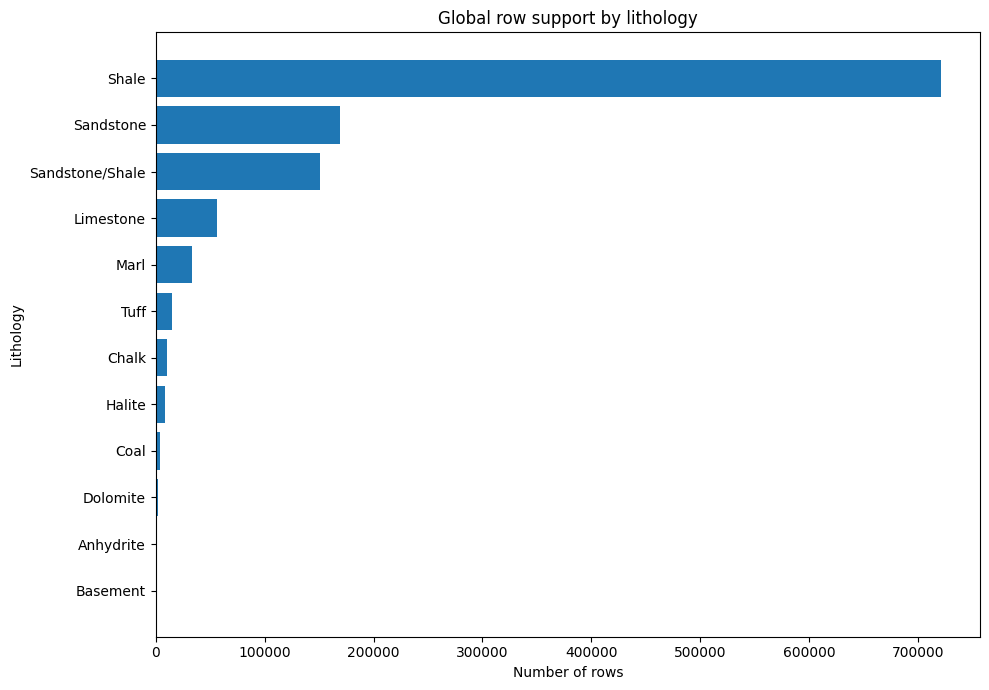

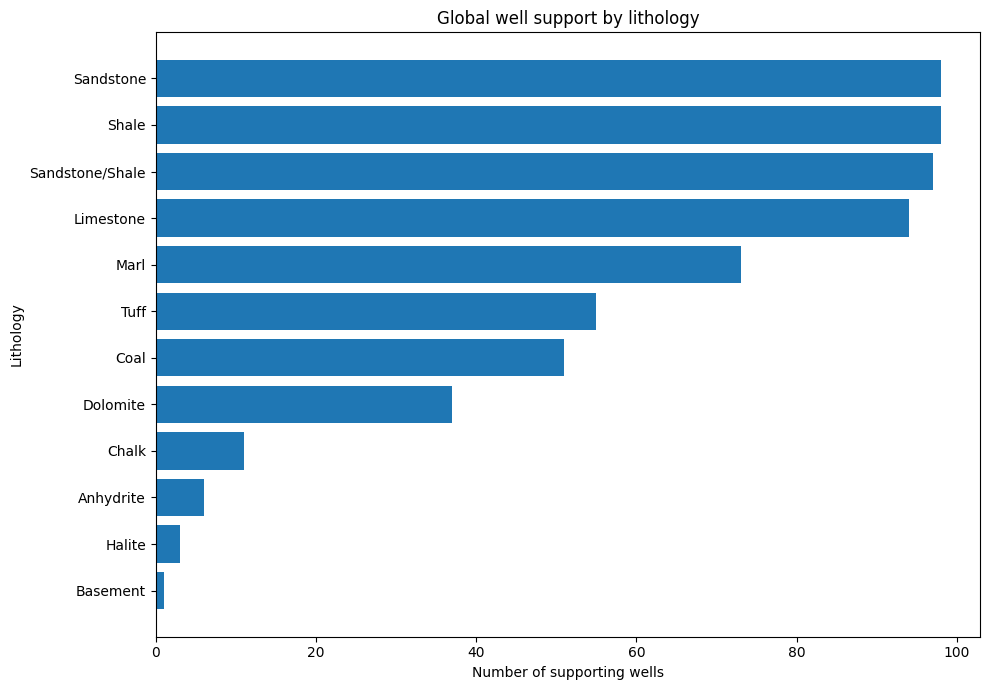

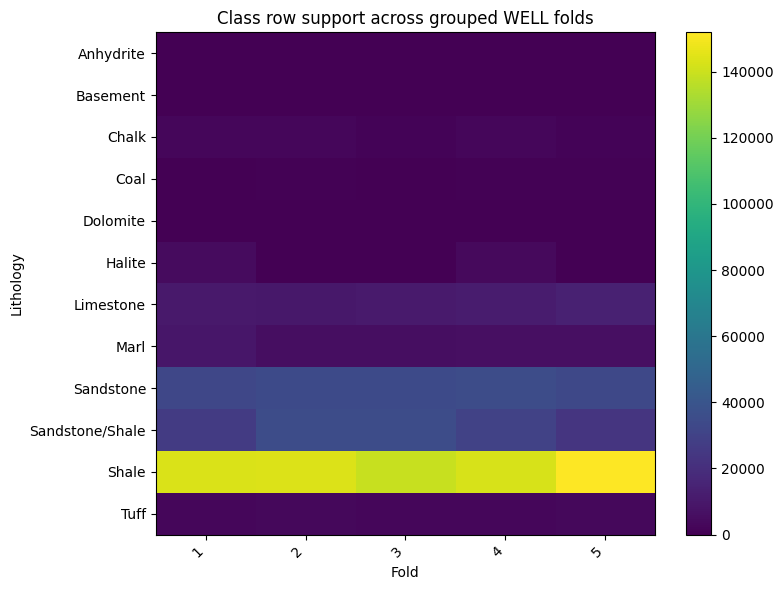

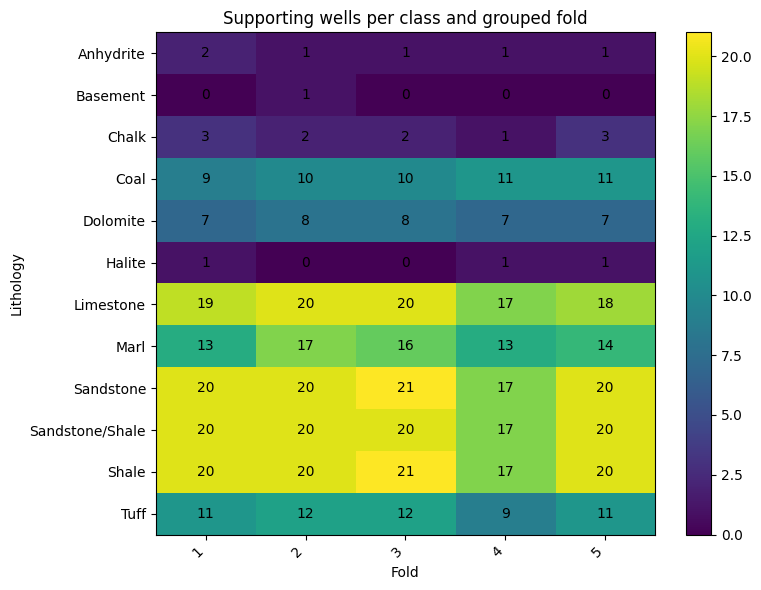

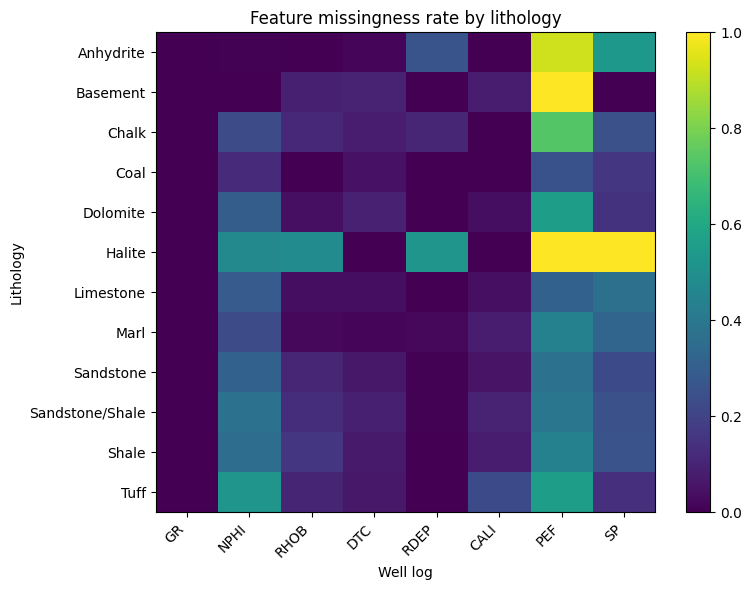

In [11]:
def save_figure(filename):
    plt.tight_layout()
    plt.savefig(PLOT_DIR / filename, dpi=220, bbox_inches="tight")
    plt.show()
    plt.close()


def heatmap(df, title, xlabel, ylabel, filename, annotate=False, fmt=".0f"):
    values = df.to_numpy(dtype=float)
    plt.figure(
        figsize=(
            max(8, 0.75 * df.shape[1]),
            max(6, 0.48 * df.shape[0]),
        )
    )
    image = plt.imshow(values, aspect="auto")
    plt.colorbar(image)
    plt.xticks(np.arange(df.shape[1]), df.columns, rotation=45, ha="right")
    plt.yticks(np.arange(df.shape[0]), df.index)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)

    if annotate:
        for i in range(df.shape[0]):
            for j in range(df.shape[1]):
                value = values[i, j]
                if np.isfinite(value):
                    plt.text(j, i, format(value, fmt), ha="center", va="center")

    save_figure(filename)


# Plot 01
plot_df = class_global_summary.sort_values("rows")
plt.figure(figsize=(10, 7))
plt.barh(plot_df["LITHOLOGY_NAME"], plot_df["rows"])
plt.xlabel("Number of rows")
plt.ylabel("Lithology")
plt.title("Global row support by lithology")
save_figure("01_global_class_row_support.png")

# Plot 02
plot_df = class_global_summary.sort_values("wells")
plt.figure(figsize=(10, 7))
plt.barh(plot_df["LITHOLOGY_NAME"], plot_df["wells"])
plt.xlabel("Number of supporting wells")
plt.ylabel("Lithology")
plt.title("Global well support by lithology")
save_figure("02_global_class_well_support.png")

# Plot 03
fold_rows = (
    fold_class_summary.pivot(
        index="LITHOLOGY_NAME", columns="GROUP_FOLD", values="rows"
    ).fillna(0)
)
heatmap(
    fold_rows,
    "Class row support across grouped WELL folds",
    "Fold",
    "Lithology",
    "03_fold_class_row_support_heatmap.png",
)

# Plot 04
fold_wells = (
    fold_class_summary.pivot(
        index="LITHOLOGY_NAME", columns="GROUP_FOLD", values="wells"
    ).fillna(0)
)
heatmap(
    fold_wells,
    "Supporting wells per class and grouped fold",
    "Fold",
    "Lithology",
    "04_fold_class_well_support_heatmap.png",
    annotate=True,
)

# Plot 05
missingness = (
    feature_class_missingness.pivot(
        index="LITHOLOGY_NAME", columns="feature", values="missing_rate"
    ).reindex(columns=ACTIVE_FEATURES)
)
heatmap(
    missingness,
    "Feature missingness rate by lithology",
    "Well log",
    "Lithology",
    "05_feature_missingness_by_class_heatmap.png",
)

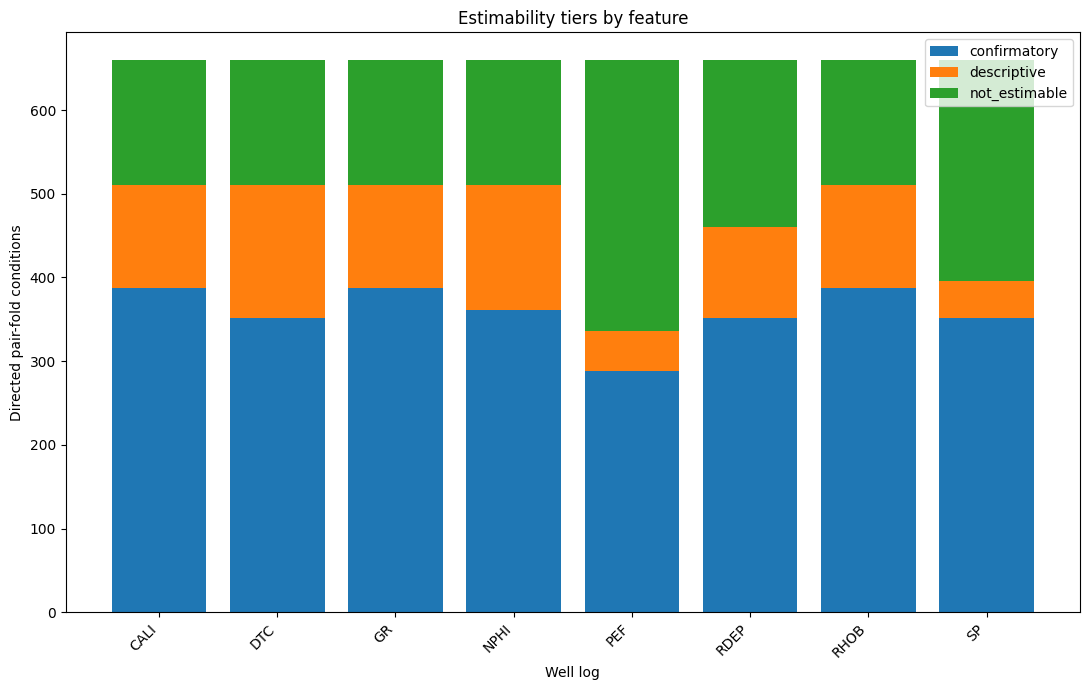

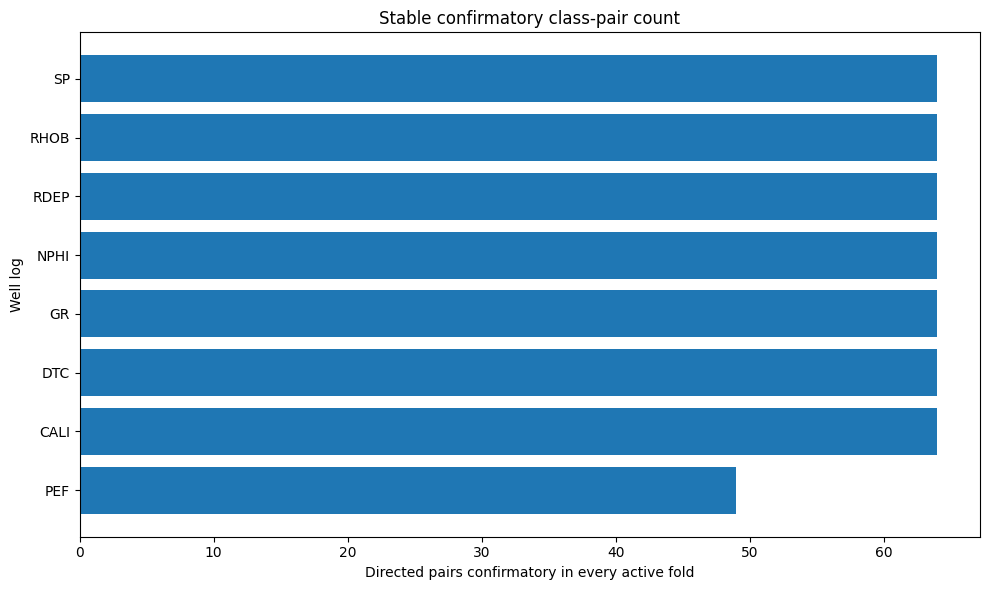

In [12]:
# Plot 06 — Tier counts
tier_pivot = (
    tier_counts.pivot(
        index="feature", columns="analysis_tier", values="pair_fold_conditions"
    )
    .fillna(0)
    .reindex(
        columns=["confirmatory", "descriptive", "not_estimable"],
        fill_value=0,
    )
)

plt.figure(figsize=(11, 7))
bottom = np.zeros(len(tier_pivot))
for tier in tier_pivot.columns:
    values = tier_pivot[tier].to_numpy()
    plt.bar(tier_pivot.index, values, bottom=bottom, label=tier)
    bottom += values

plt.xlabel("Well log")
plt.ylabel("Directed pair-fold conditions")
plt.title("Estimability tiers by feature")
plt.xticks(rotation=45, ha="right")
plt.legend()
save_figure("06_pair_tier_counts_by_feature.png")

# Plot 07 — Stable pair count
plot_df = feature_stability_summary.sort_values("stable_confirmatory_pairs")
plt.figure(figsize=(10, 6))
plt.barh(plot_df["feature"], plot_df["stable_confirmatory_pairs"])
plt.xlabel("Directed pairs confirmatory in every active fold")
plt.ylabel("Well log")
plt.title("Stable confirmatory class-pair count")
save_figure("07_stable_confirmatory_pair_count.png")

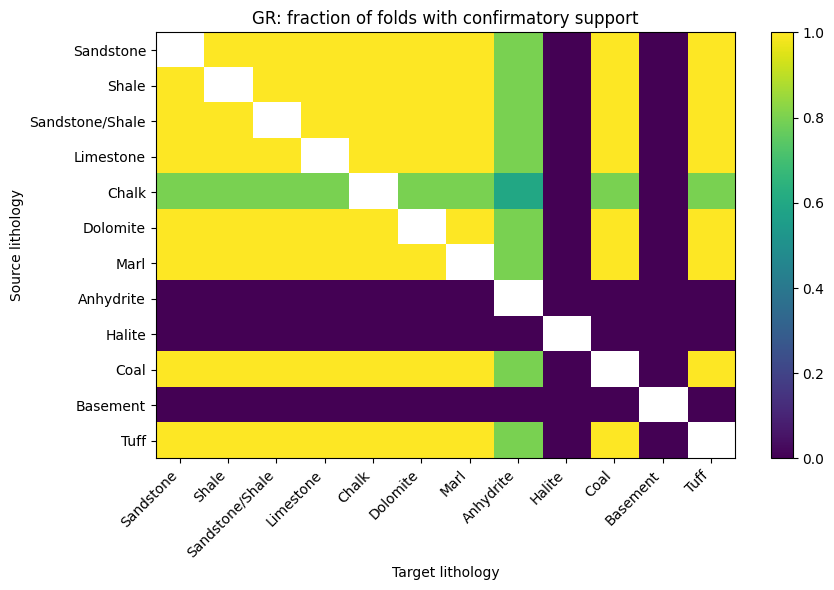

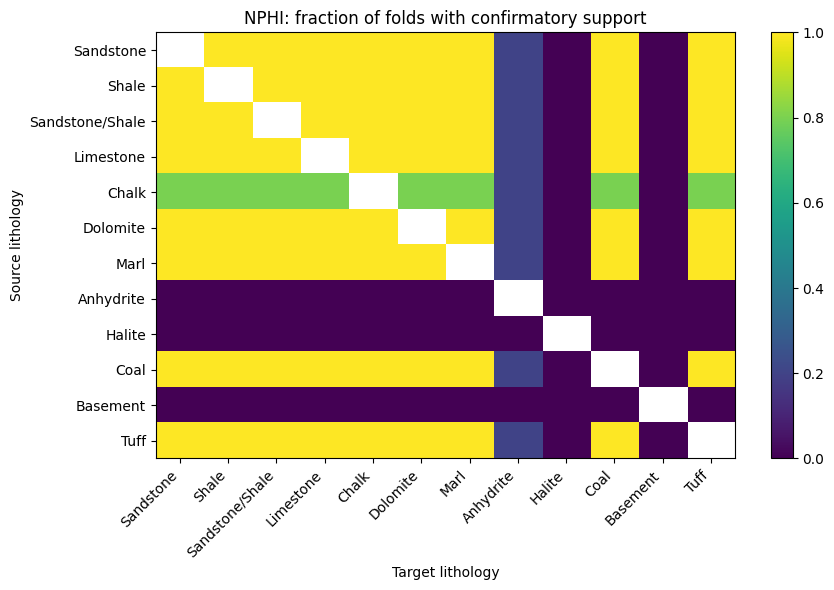

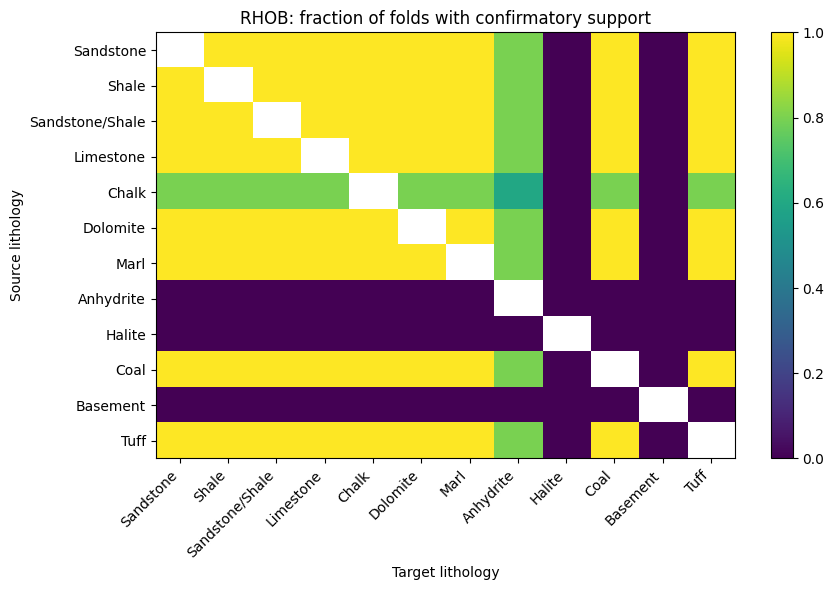

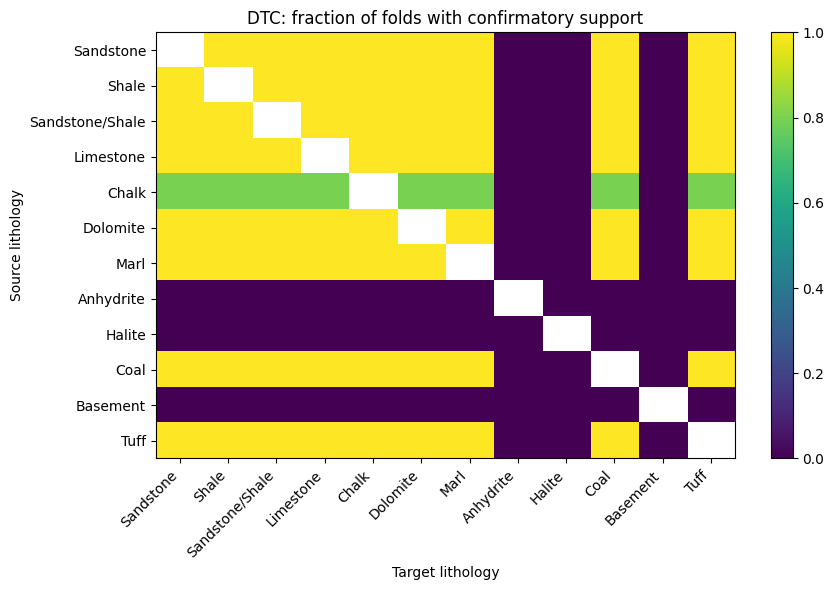

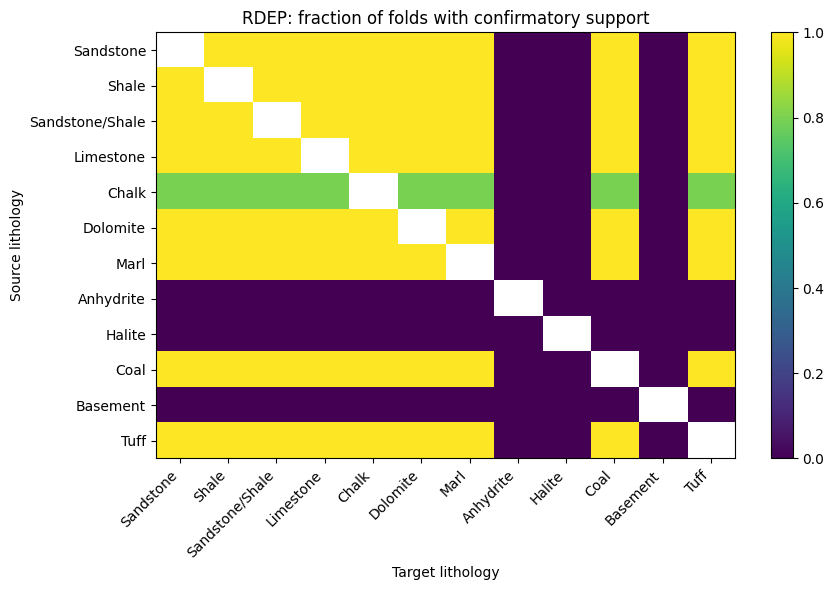

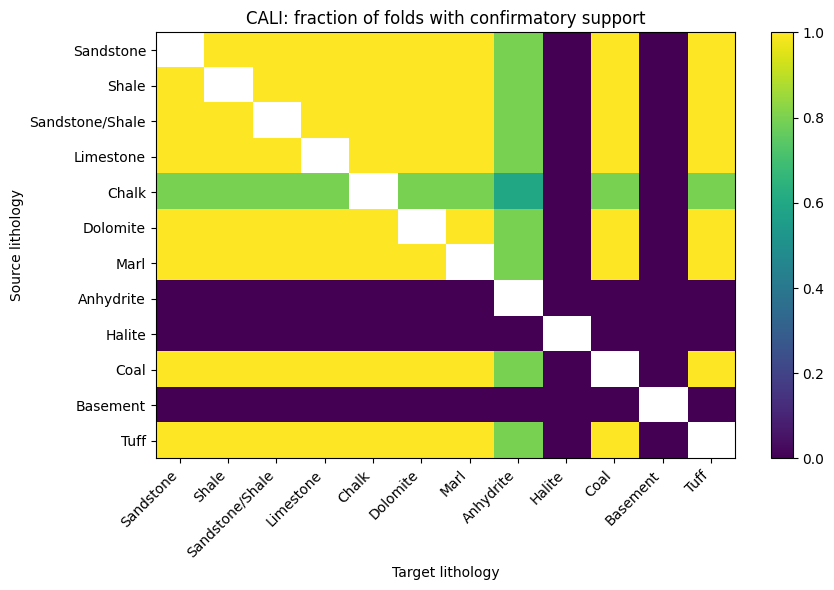

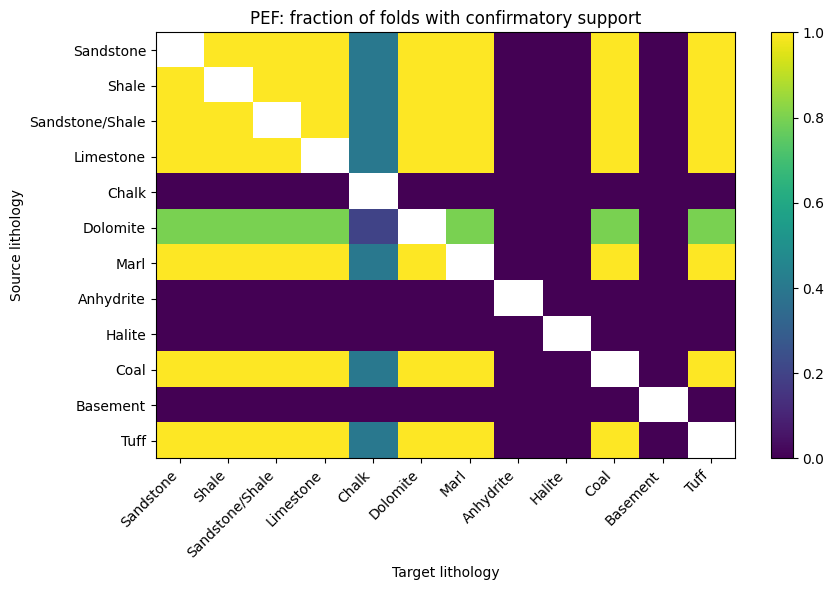

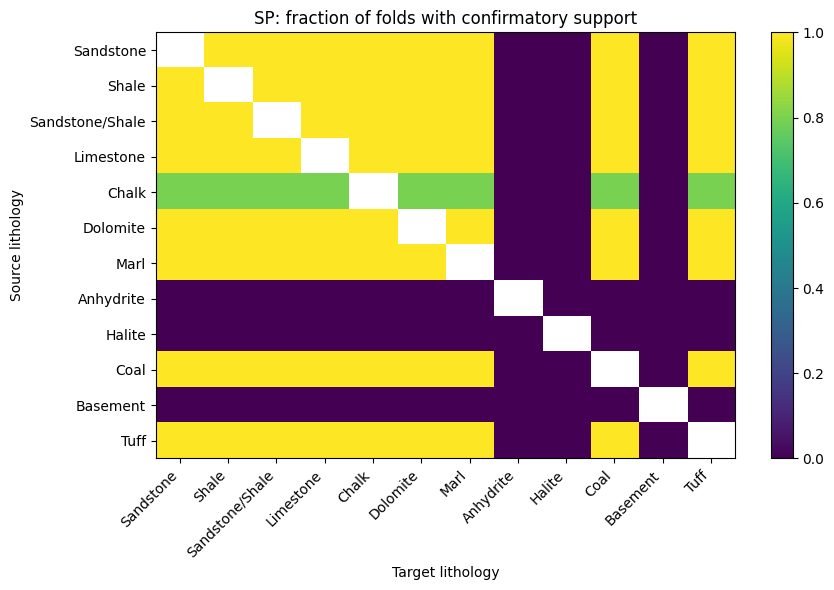

In [13]:
# Plot 08 — یک Matrix جهت‌دار برای هر Log
class_order = [LITHOLOGY_NAMES[c] for c in LITHOLOGY_CODES]

for feature in ACTIVE_FEATURES:
    matrix = (
        pair_stability_summary.loc[
            pair_stability_summary["feature"] == feature
        ]
        .pivot(
            index="source_name",
            columns="target_name",
            values="confirmatory_fraction",
        )
        .reindex(index=class_order, columns=class_order)
    )
    heatmap(
        matrix,
        f"{feature}: fraction of folds with confirmatory support",
        "Target lithology",
        "Source lithology",
        f"08_pair_confirmatory_fraction_{feature}.png",
    )

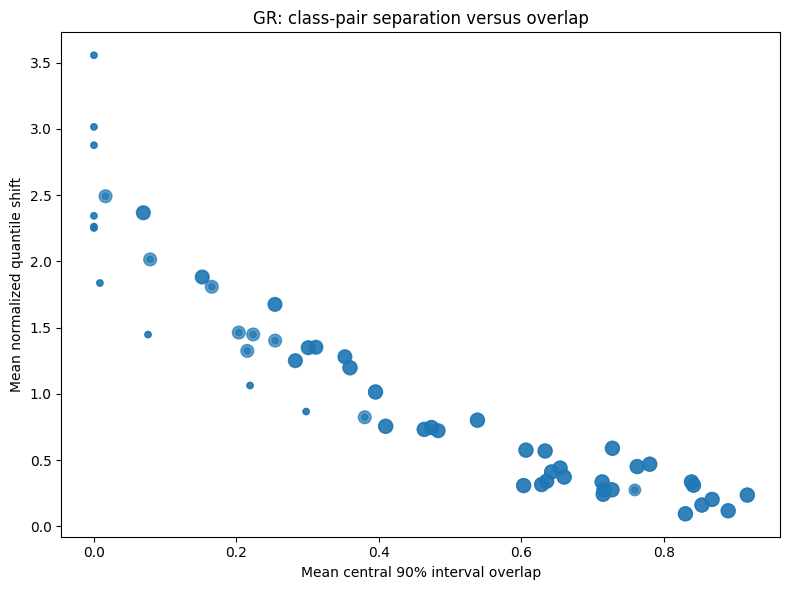

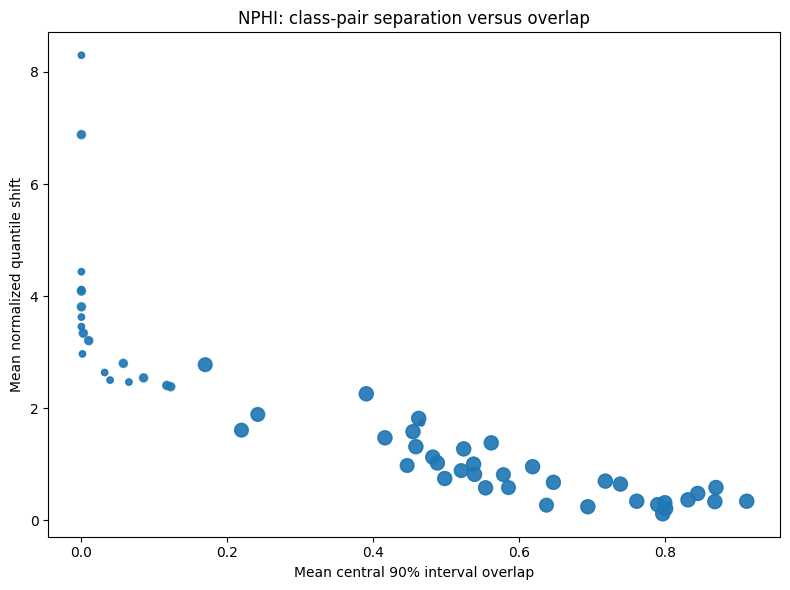

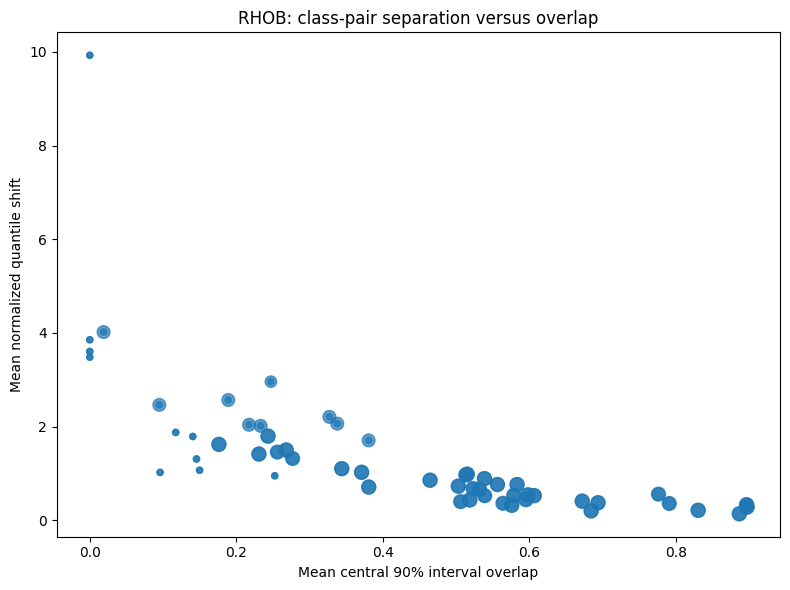

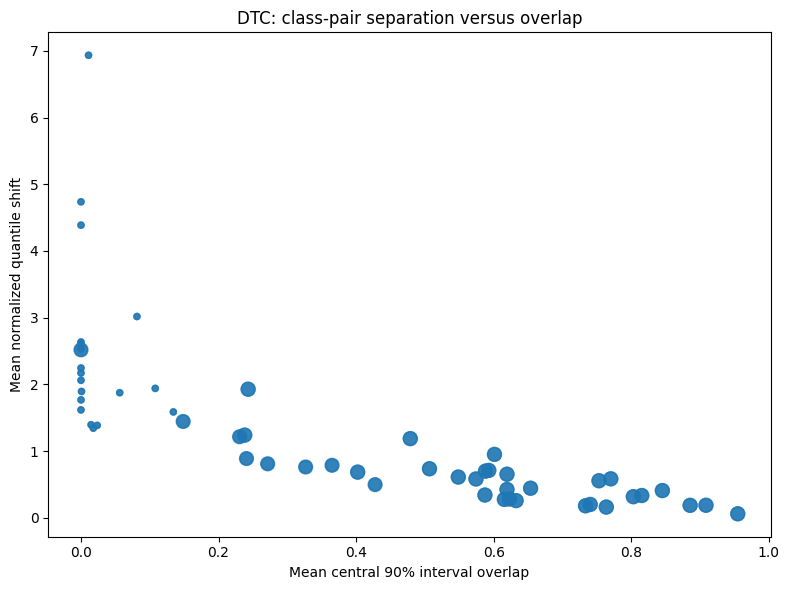

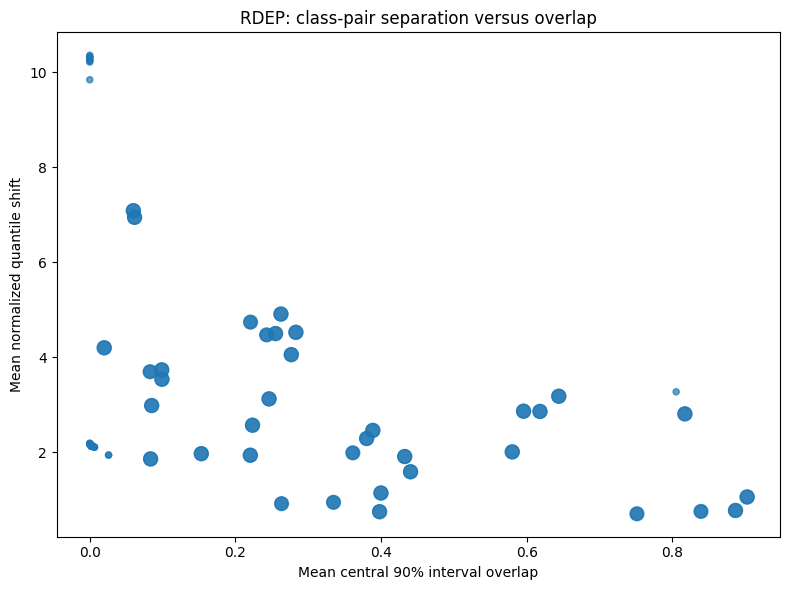

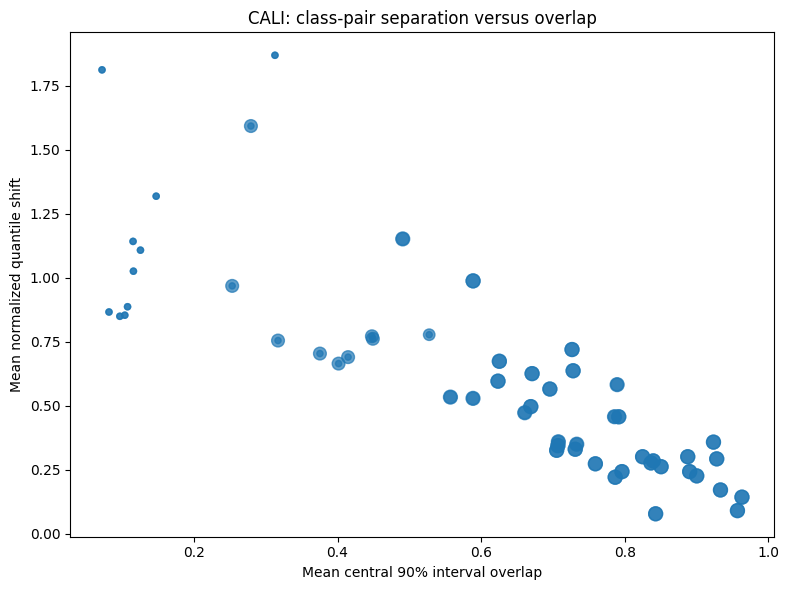

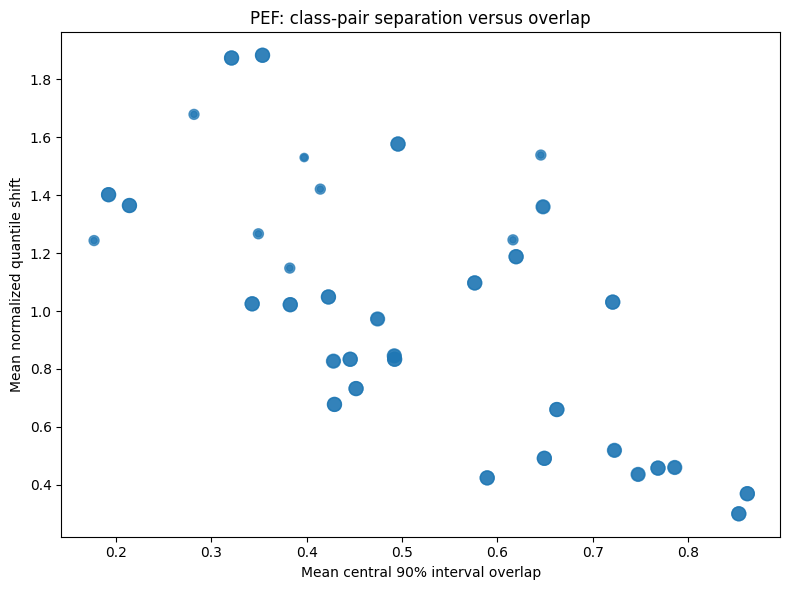

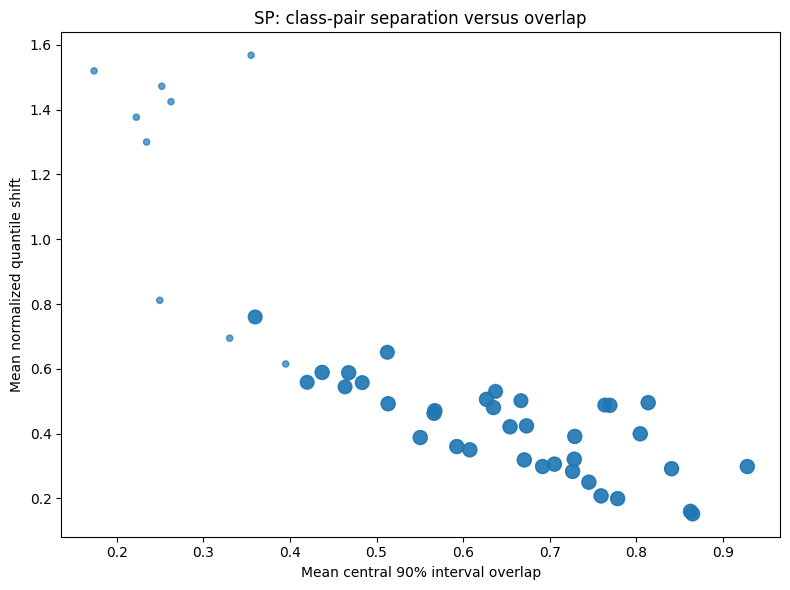

In [14]:
# Plot 09 — فاصله توزیعی در برابر overlap برای هر Log
estimable = pair_stability_summary.loc[
    pair_stability_summary["descriptive_or_better_fraction"] > 0
]

for feature in ACTIVE_FEATURES:
    frame = estimable.loc[estimable["feature"] == feature]
    if frame.empty:
        continue

    plt.figure(figsize=(8, 6))
    plt.scatter(
        frame["mean_central_overlap"],
        frame["mean_normalized_quantile_shift"],
        s=20 + 80 * frame["confirmatory_fraction"],
        alpha=0.7,
    )
    plt.xlabel("Mean central 90% interval overlap")
    plt.ylabel("Mean normalized quantile shift")
    plt.title(f"{feature}: class-pair separation versus overlap")
    save_figure(f"09_pair_separation_overlap_{feature}.png")

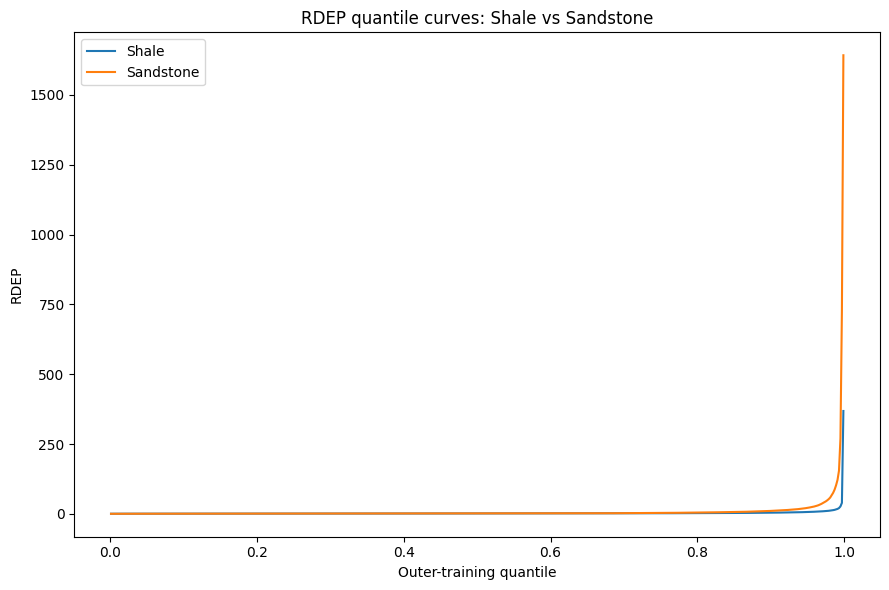

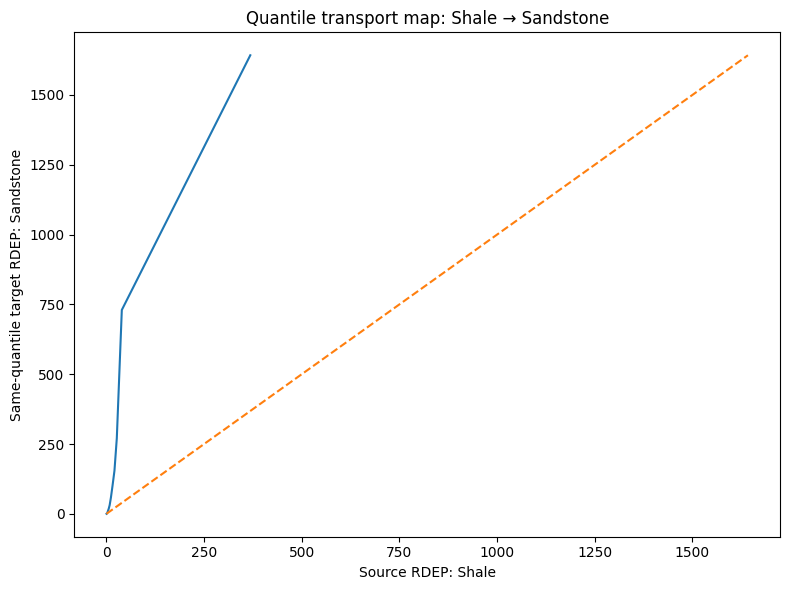

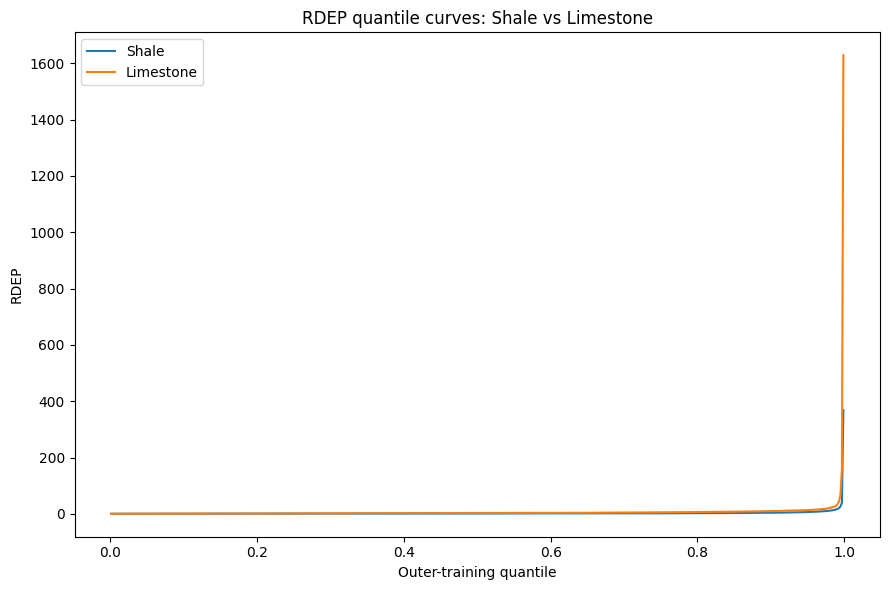

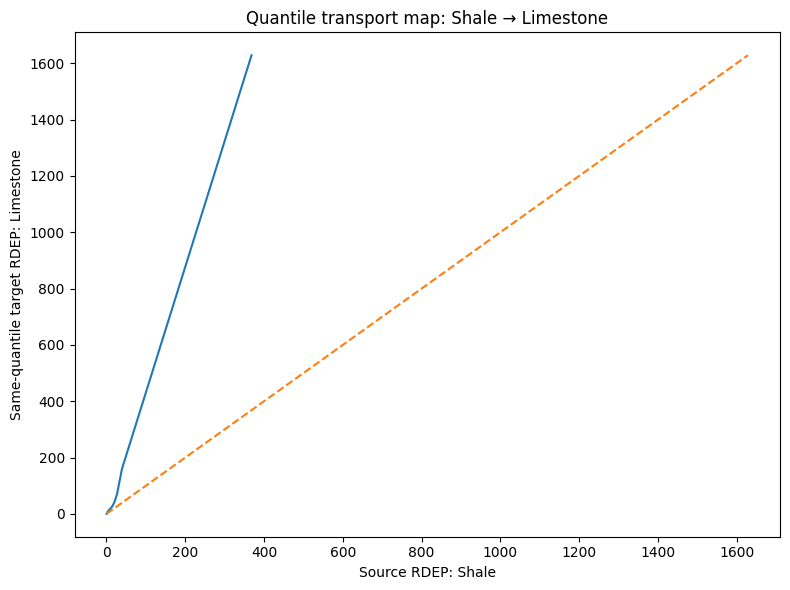

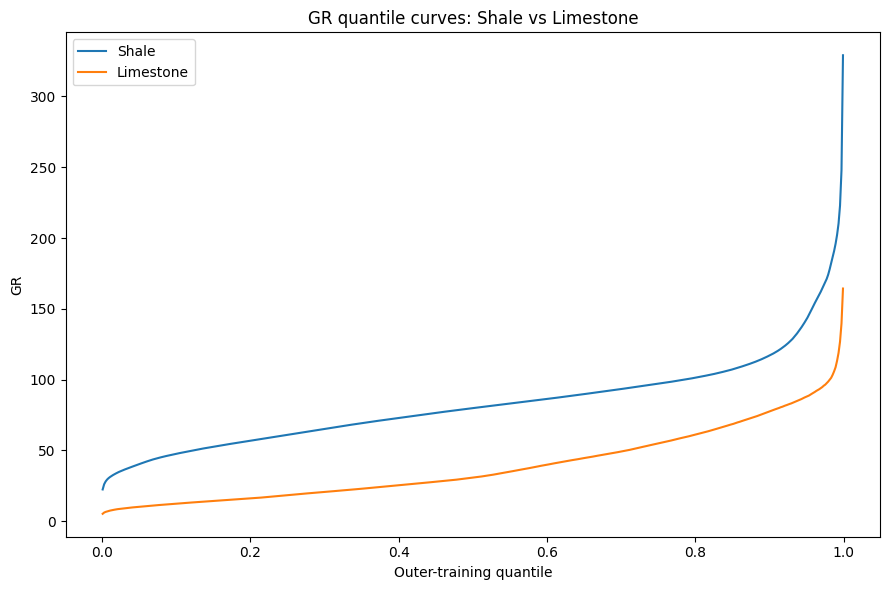

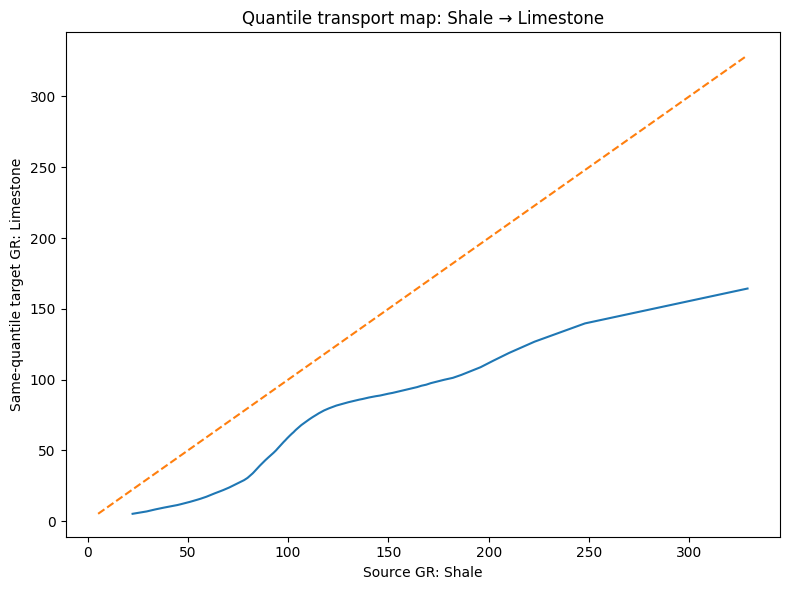

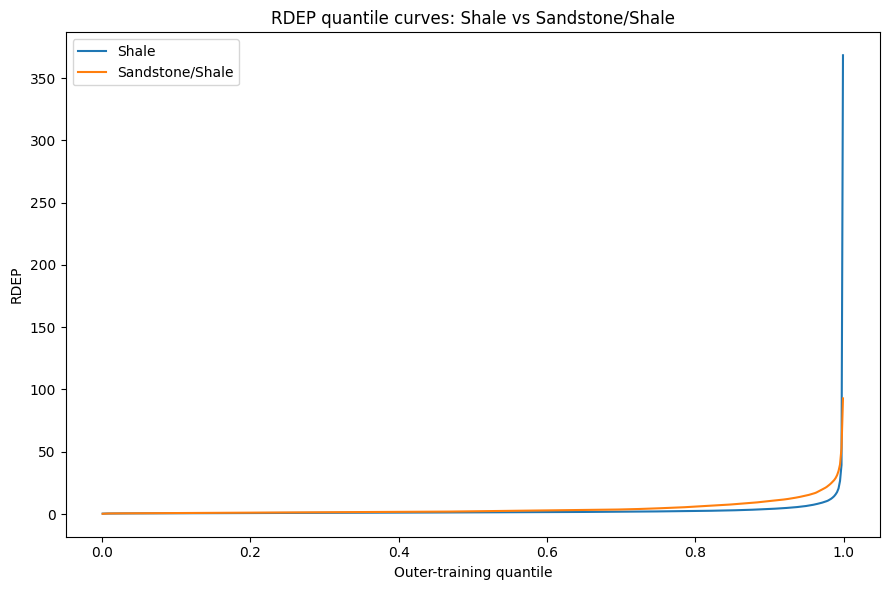

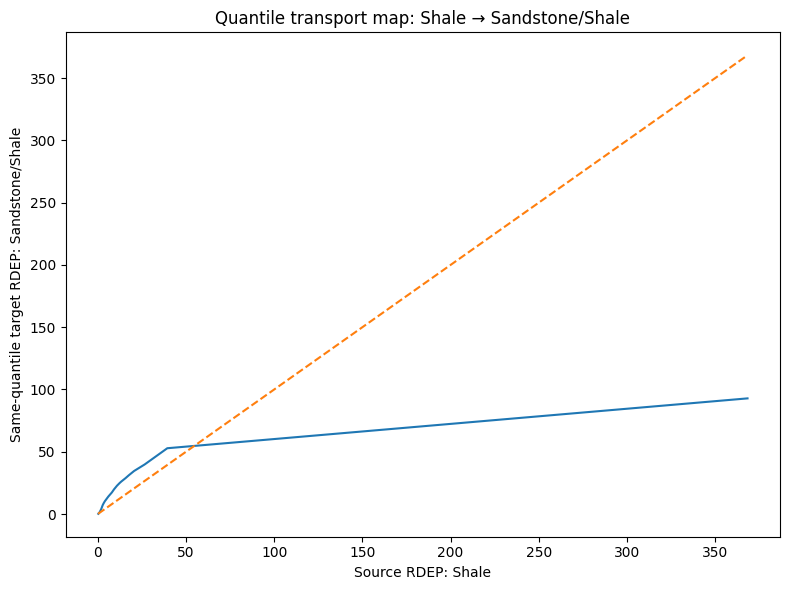

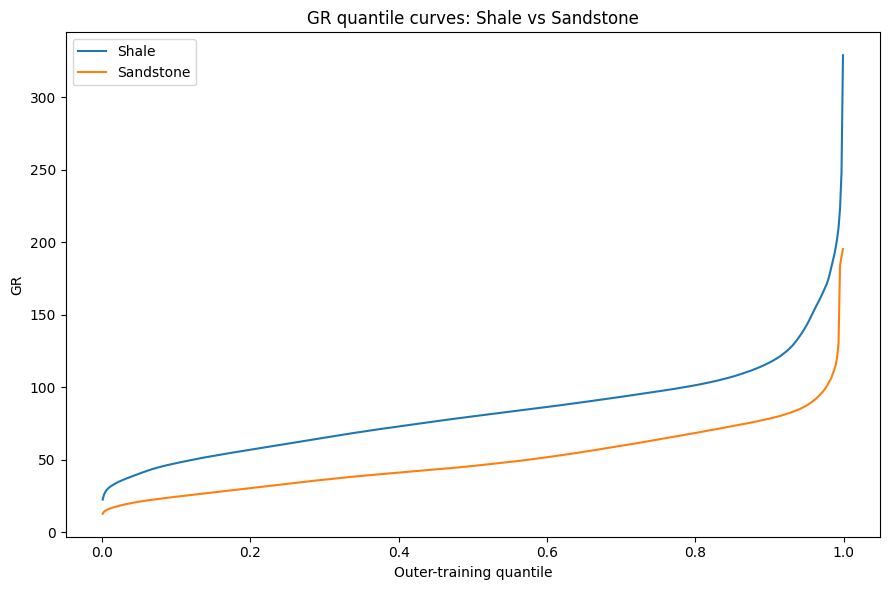

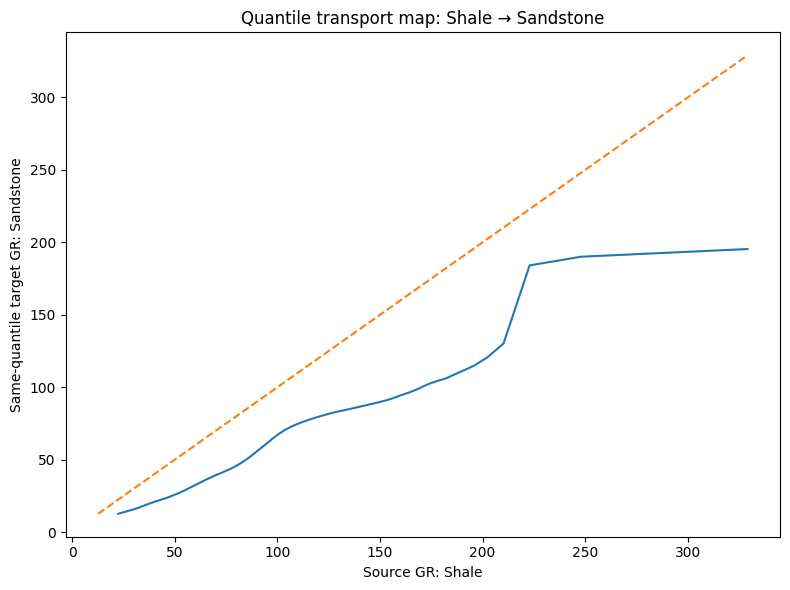

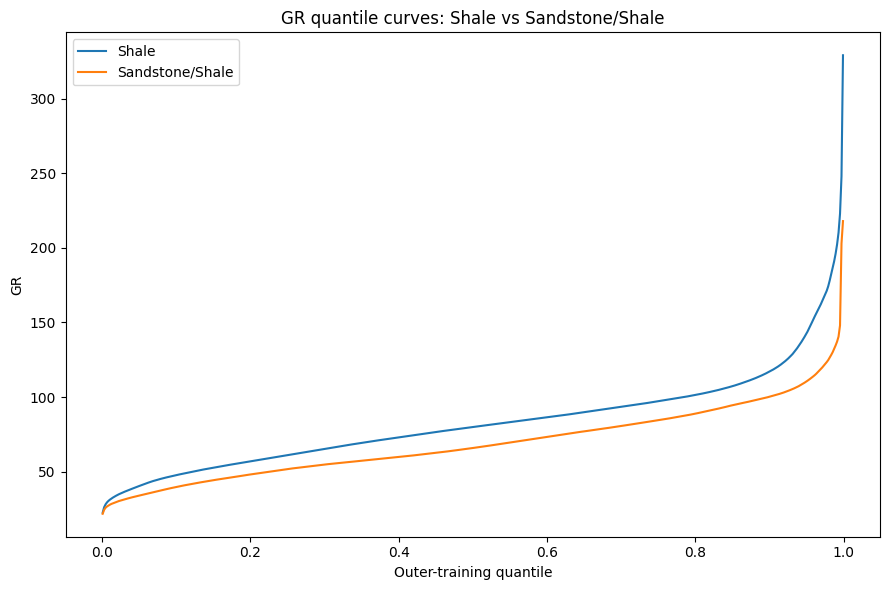

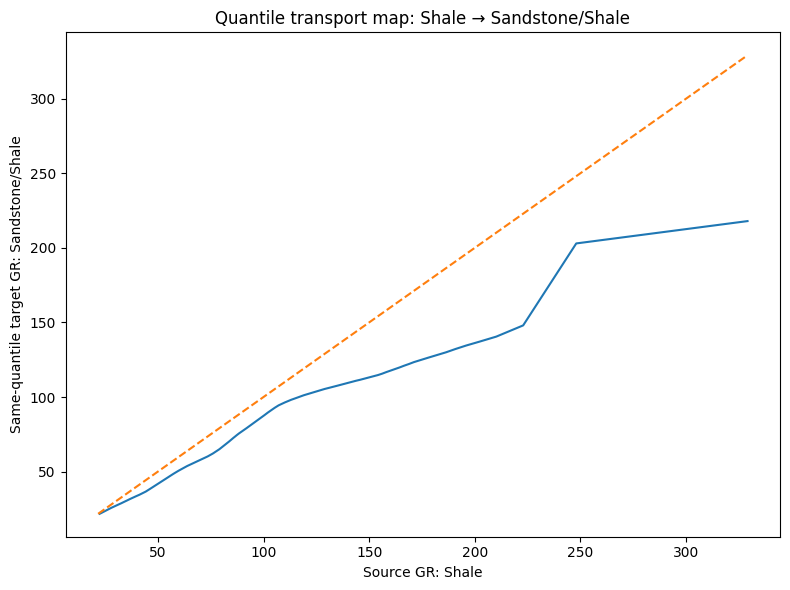

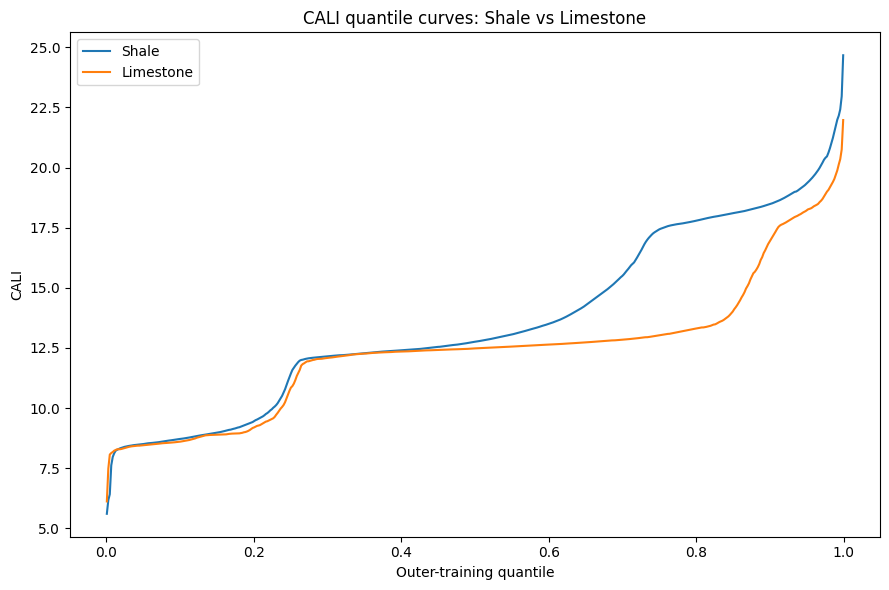

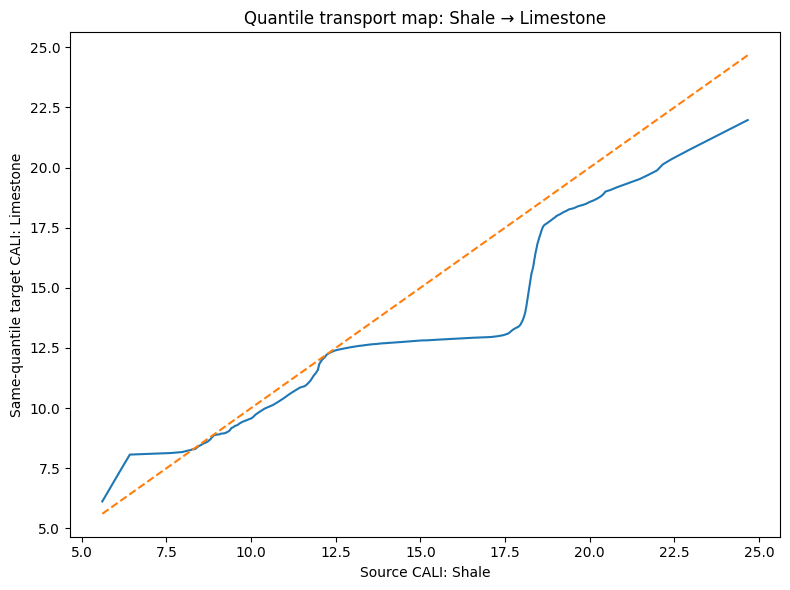

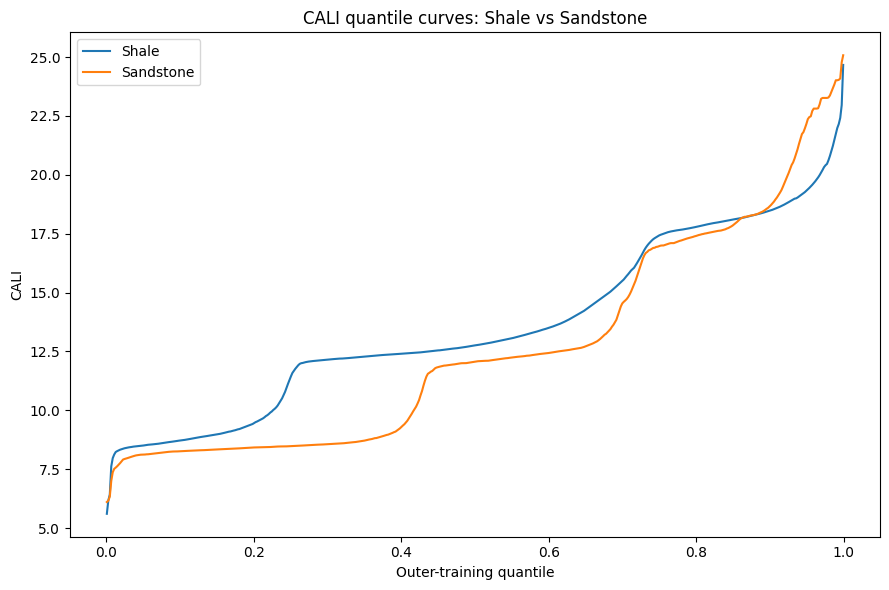

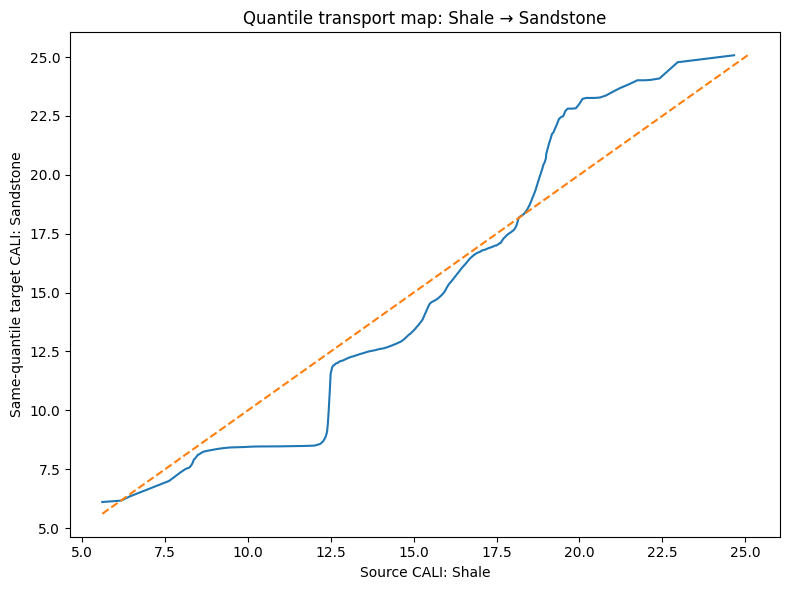

In [15]:
# Plotهای 10 و 11 — Quantile diagnostics برای Pairهای پیشنهادی
if not recommended_pilot_pairs.empty:
    diagnostics = (
        recommended_pilot_pairs.sort_values(
            [
                "confirmatory_fraction",
                "minimum_source_validation_rows",
                "mean_normalized_quantile_shift",
            ],
            ascending=[False, False, False],
        )
        .head(MAX_GLOBAL_PAIR_DIAGNOSTICS)
    )

    for _, row in diagnostics.iterrows():
        feature = row["feature"]
        source_code = int(row["source_code"])
        target_code = int(row["target_code"])
        source_name = row["source_name"]
        target_name = row["target_name"]

        candidates = directed_pair_registry.loc[
            (directed_pair_registry["feature"] == feature)
            & (directed_pair_registry["source_code"] == source_code)
            & (directed_pair_registry["target_code"] == target_code)
            & (directed_pair_registry["analysis_tier"] == "confirmatory")
        ].sort_values(
            [
                "source_validation_observed_wells",
                "source_validation_observed_rows",
            ],
            ascending=[False, False],
        )

        if candidates.empty:
            continue

        fold = int(candidates.iloc[0]["outer_fold"])
        source_q = quantile_lookup[(fold, feature, source_code)]
        target_q = quantile_lookup[(fold, feature, target_code)]

        safe = (
            f"{feature}__{source_name}_to_{target_name}__fold_{fold}"
            .replace("/", "_")
            .replace(" ", "_")
        )

        plt.figure(figsize=(9, 6))
        plt.plot(QUANTILE_GRID, source_q, label=source_name)
        plt.plot(QUANTILE_GRID, target_q, label=target_name)
        plt.xlabel("Outer-training quantile")
        plt.ylabel(feature)
        plt.title(
            f"{feature} quantile curves: {source_name} vs {target_name}"
        )
        plt.legend()
        save_figure(f"10_quantile_curves__{safe}.png")

        plt.figure(figsize=(8, 6))
        plt.plot(source_q, target_q)
        minimum = min(float(source_q.min()), float(target_q.min()))
        maximum = max(float(source_q.max()), float(target_q.max()))
        plt.plot([minimum, maximum], [minimum, maximum], linestyle="--")
        plt.xlabel(f"Source {feature}: {source_name}")
        plt.ylabel(f"Same-quantile target {feature}: {target_name}")
        plt.title(
            f"Quantile transport map: {source_name} → {target_name}"
        )
        save_figure(f"11_transport_mapping__{safe}.png")

# 10. Registry Gate و ذخیره خروجی‌ها

In [16]:
expected_pair_rows = (
    len(ACTIVE_OUTER_FOLDS)
    * len(ACTIVE_FEATURES)
    * len(LITHOLOGY_CODES)
    * (len(LITHOLOGY_CODES) - 1)
)

key_columns = ["outer_fold", "feature", "source_code", "target_code"]
duplicate_keys = int(
    directed_pair_registry.duplicated(subset=key_columns).sum()
)

REGISTRY_GATE = {
    "official_test_unused": True,
    "all_requested_features_present": len(missing_features) == 0,
    "all_five_grouped_folds_present_in_train": (
        sorted(train_raw["GROUP_FOLD"].unique().tolist()) == [1, 2, 3, 4, 5]
    ),
    "expected_directed_pair_rows": int(expected_pair_rows),
    "observed_directed_pair_rows": int(len(directed_pair_registry)),
    "directed_pair_row_count_correct": (
        len(directed_pair_registry) == expected_pair_rows
    ),
    "duplicate_pair_keys": duplicate_keys,
    "no_duplicate_pair_keys": duplicate_keys == 0,
    "no_self_pairs": bool(
        (
            directed_pair_registry["source_code"]
            != directed_pair_registry["target_code"]
        ).all()
    ),
    "quantile_registry_nonempty": len(class_quantile_registry) > 0,
    "confirmatory_pairs_available": bool(
        (directed_pair_registry["analysis_tier"] == "confirmatory").any()
    ),
    "recommended_pilot_pairs_available": len(recommended_pilot_pairs) > 0,
}

REGISTRY_GATE["overall_registry_passed"] = all(
    [
        REGISTRY_GATE["official_test_unused"],
        REGISTRY_GATE["all_requested_features_present"],
        REGISTRY_GATE["all_five_grouped_folds_present_in_train"],
        REGISTRY_GATE["directed_pair_row_count_correct"],
        REGISTRY_GATE["no_duplicate_pair_keys"],
        REGISTRY_GATE["no_self_pairs"],
        REGISTRY_GATE["quantile_registry_nonempty"],
        REGISTRY_GATE["confirmatory_pairs_available"],
        REGISTRY_GATE["recommended_pilot_pairs_available"],
    ]
)

print(json.dumps(REGISTRY_GATE, indent=2))

if not REGISTRY_GATE["overall_registry_passed"]:
    raise RuntimeError("Class-pair registry gate failed.")

confirmatory_registry = directed_pair_registry.loc[
    directed_pair_registry["analysis_tier"] == "confirmatory"
].copy()
descriptive_registry = directed_pair_registry.loc[
    directed_pair_registry["analysis_tier"] == "descriptive"
].copy()
not_estimable_registry = directed_pair_registry.loc[
    directed_pair_registry["analysis_tier"] == "not_estimable"
].copy()

class_global_summary.to_csv(
    OUTPUT_DIR / "00_global_class_support.csv", index=False
)
fold_class_summary.to_csv(
    OUTPUT_DIR / "01_fold_class_support.csv", index=False
)
feature_class_missingness.to_csv(
    OUTPUT_DIR / "02_feature_class_missingness.csv", index=False
)
class_fold_feature_support.to_csv(
    OUTPUT_DIR / "03_class_fold_feature_support.csv", index=False
)
class_quantile_registry.to_parquet(
    OUTPUT_DIR / "04_fold_safe_class_quantile_registry.parquet",
    index=False,
)
directed_pair_registry.to_csv(
    OUTPUT_DIR / "05_directed_pair_support_registry.csv", index=False
)
pair_stability_summary.to_csv(
    OUTPUT_DIR / "06_pair_stability_summary.csv", index=False
)
confirmatory_registry.to_csv(
    OUTPUT_DIR / "07_confirmatory_pair_registry.csv", index=False
)
descriptive_registry.to_csv(
    OUTPUT_DIR / "08_descriptive_pair_registry.csv", index=False
)
not_estimable_registry.to_csv(
    OUTPUT_DIR / "09_not_estimable_pair_registry.csv", index=False
)
recommended_pilot_pairs.to_csv(
    OUTPUT_DIR / "10_recommended_pilot_pairs.csv", index=False
)
feature_stability_summary.to_csv(
    OUTPUT_DIR / "11_feature_stability_summary.csv", index=False
)
tier_counts.to_csv(
    OUTPUT_DIR / "12_pair_tier_counts.csv", index=False
)

with open(
    OUTPUT_DIR / "13_registry_gate.json", "w", encoding="utf-8"
) as file:
    json.dump(REGISTRY_GATE, file, ensure_ascii=False, indent=2)

run_configuration = {
    "stage": "04B_class_pair_support_and_quantile_transport_registry",
    "run_mode": RUN_MODE,
    "official_test_used": False,
    "outer_folds": ACTIVE_OUTER_FOLDS,
    "features": ACTIVE_FEATURES,
    "classes": LITHOLOGY_CODES,
    "directed_pairs_per_feature": (
        len(LITHOLOGY_CODES) * (len(LITHOLOGY_CODES) - 1)
    ),
    "quantile_grid": {
        "minimum": float(QUANTILE_GRID.min()),
        "maximum": float(QUANTILE_GRID.max()),
        "points": int(len(QUANTILE_GRID)),
    },
    "confirmatory_policy": {
        "minimum_train_observed_rows_per_class": (
            CONFIRMATORY_MIN_TRAIN_ROWS_PER_CLASS
        ),
        "minimum_train_observed_wells_per_class": (
            CONFIRMATORY_MIN_TRAIN_WELLS_PER_CLASS
        ),
        "minimum_source_validation_observed_rows": (
            CONFIRMATORY_MIN_SOURCE_VALIDATION_ROWS
        ),
        "minimum_source_validation_observed_wells": (
            CONFIRMATORY_MIN_SOURCE_VALIDATION_WELLS
        ),
    },
    "descriptive_policy": {
        "minimum_train_observed_rows_per_class": (
            DESCRIPTIVE_MIN_TRAIN_ROWS_PER_CLASS
        ),
        "minimum_train_observed_wells_per_class": (
            DESCRIPTIVE_MIN_TRAIN_WELLS_PER_CLASS
        ),
        "minimum_source_validation_observed_rows": (
            DESCRIPTIVE_MIN_SOURCE_VALIDATION_ROWS
        ),
        "minimum_source_validation_observed_wells": (
            DESCRIPTIVE_MIN_SOURCE_VALIDATION_WELLS
        ),
    },
    "transport_mapping_source": "outer-training wells only",
    "next_stage": "04C_shared_class_conditional_transport_bank",
}

with open(
    OUTPUT_DIR / "14_run_configuration.json", "w", encoding="utf-8"
) as file:
    json.dump(run_configuration, file, ensure_ascii=False, indent=2)

print("\n✅ Registry passed.")
print("Outputs:", OUTPUT_DIR)
print("Plots:", PLOT_DIR)

{
  "official_test_unused": true,
  "all_requested_features_present": true,
  "all_five_grouped_folds_present_in_train": true,
  "expected_directed_pair_rows": 5280,
  "observed_directed_pair_rows": 5280,
  "directed_pair_row_count_correct": true,
  "duplicate_pair_keys": 0,
  "no_duplicate_pair_keys": true,
  "no_self_pairs": true,
  "quantile_registry_nonempty": true,
  "confirmatory_pairs_available": true,
  "recommended_pilot_pairs_available": true,
  "overall_registry_passed": true
}

✅ Registry passed.
Outputs: ${STRATASHIFT_ARTIFACT_ROOT}/04B_class_pair_support_transport_registry/full
Plots: ${STRATASHIFT_ARTIFACT_ROOT}/04B_class_pair_support_transport_registry/full/plots


# فایل‌هایی که بعد از اجرا باید ارسال شوند

از مسیر:

```text
${STRATASHIFT_ARTIFACT_ROOT}/
04B_class_pair_support_transport_registry/full
```

این فایل‌ها را ارسال کن:

```text
00_global_class_support.csv
02_feature_class_missingness.csv
03_class_fold_feature_support.csv
05_directed_pair_support_registry.csv
06_pair_stability_summary.csv
07_confirmatory_pair_registry.csv
10_recommended_pilot_pairs.csv
11_feature_stability_summary.csv
12_pair_tier_counts.csv
13_registry_gate.json
14_run_configuration.json
```

پوشه `plots` را نیز نگه دار. تصاویر مهم برای بررسی سریع:

```text
03_fold_class_row_support_heatmap.png
04_fold_class_well_support_heatmap.png
05_feature_missingness_by_class_heatmap.png
06_pair_tier_counts_by_feature.png
07_stable_confirmatory_pair_count.png
08_pair_confirmatory_fraction_GR.png
09_pair_separation_overlap_GR.png
10_quantile_curves__*.png
11_transport_mapping__*.png
```

بعد از بررسی Registry، نوت‌بوک `04C` مقادیر مداخله‌شده را برای Doseهای مختلف می‌سازد.